# Flight Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the original dataset
raw_df = pd.read_csv("D:/inomat_AS/flight_Project/dataset/Flight_Delays_50K.csv")

# Create a working copy for cleaning and analysis
df = raw_df.copy()

In [2]:
df.head()# these are the first 5 records of the dataset

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,5,14,4,US,1721,N174US,CLT,SMF,1810,...,2043.0,4.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,11,29,7,MQ,3363,N902MQ,LEX,ORD,1837,...,1942.0,17.0,0,0,NaN,0.0,0.0,0.0,17.0,0.0
2,2015,2,10,2,US,1933,N562UW,PHL,ORD,730,...,834.0,-28.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,12,21,1,UA,1929,N460UA,SEA,EWR,622,...,1414.0,-17.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,5,7,4,DL,1478,N67171,ATL,PHL,725,...,920.0,-5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.tail()#these are the last 5 records of the dataset

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
49995,2015,6,15,1,OO,4567,N554CA,SLC,ORD,2005,...,NaN,NaN,0,1,B,NaN,NaN,NaN,NaN,NaN
49996,2015,4,23,4,WN,561,N288WN,MSY,DCA,1925,...,2237.0,-18.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
49997,2015,2,19,4,WN,842,N364SW,PHX,MCI,1025,...,1403.0,13.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
49998,2015,12,12,6,WN,972,N488WN,AUS,STL,615,...,754.0,-16.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
49999,2015,5,4,1,AA,2419,N365AA,LAX,DFW,1145,...,1721.0,31.0,0,0,NaN,0.0,0.0,0.0,31.0,0.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 50000 non-null  int64  
 1   MONTH                50000 non-null  int64  
 2   DAY                  50000 non-null  int64  
 3   DAY_OF_WEEK          50000 non-null  int64  
 4   AIRLINE              50000 non-null  str    
 5   FLIGHT_NUMBER        50000 non-null  int64  
 6   TAIL_NUMBER          49871 non-null  str    
 7   ORIGIN_AIRPORT       50000 non-null  str    
 8   DESTINATION_AIRPORT  50000 non-null  str    
 9   SCHEDULED_DEPARTURE  50000 non-null  int64  
 10  DEPARTURE_TIME       49234 non-null  float64
 11  DEPARTURE_DELAY      49234 non-null  float64
 12  TAXI_OUT             49215 non-null  float64
 13  WHEELS_OFF           49215 non-null  float64
 14  SCHEDULED_TIME       50000 non-null  int64  
 15  ELAPSED_TIME         49085 non-null  float64
 1

- with is we can see that there are total 26 numberical type in which 16 are float and 10 are interger type and rest 5 are object(catogorical datatype).

In [5]:
df.describe()

,YEAR,MONTH,DAY,DAY_OF_WEEK,FLIGHT_NUMBER,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,...,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
count,50000.0,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,49234.000000,49234.000000,49215.000000,49215.000000,...,50000.00000,49182.000000,49085.00000,50000.000000,50000.000000,9100.000000,9100.000000,9100.000000,9100.000000,9100.000000
mean,2015.0,6.543440,15.68610,3.941880,2177.016720,1326.620920,1330.928728,9.086526,16.019344,1352.902387,...,1489.85644,1473.280631,3.99945,0.002420,0.015880,13.232418,0.071429,18.419121,22.633736,2.905604
std,0.0,3.395736,8.77768,1.992019,1759.888911,483.235737,496.210684,35.464728,8.805555,497.512045,...,505.73494,523.907408,37.75498,0.049134,0.125013,26.820545,1.793296,45.155575,41.287011,19.951584
min,2015.0,1.000000,1.00000,1.000000,1.000000,3.000000,1.000000,-55.000000,1.000000,1.000000,...,1.00000,1.000000,-70.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2015.0,4.000000,8.00000,2.000000,733.000000,915.000000,919.000000,-5.000000,11.000000,933.000000,...,1108.00000,1056.000000,-13.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2015.0,7.000000,16.00000,4.000000,1686.000000,1324.000000,1327.000000,-2.000000,14.000000,1340.000000,...,1518.00000,1510.000000,-5.00000,0.000000,0.000000,2.000000,0.000000,2.000000,3.000000,0.000000
75%,2015.0,9.000000,23.00000,6.000000,3246.000000,1730.000000,1737.000000,7.000000,19.000000,1751.000000,...,1915.00000,1913.000000,8.00000,0.000000,0.000000,18.000000,0.000000,19.000000,28.000000,0.000000
max,2015.0,12.000000,31.00000,7.000000,8410.000000,2359.000000,2400.000000,1515.000000,149.000000,2400.000000,...,2359.00000,2400.000000,1574.00000,1.000000,1.000000,532.000000,129.000000,1515.000000,765.000000,510.000000


In [6]:
df.shape

(50000, 31)

- with this we can say that the data set is having 50000 rows(records) and 31 columns(features)

In [7]:
df.columns

Index(['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'FLIGHT_NUMBER',
       'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT',
       'SCHEDULED_DEPARTURE', 'DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT',
       'WHEELS_OFF', 'SCHEDULED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE',
       'WHEELS_ON', 'TAXI_IN', 'SCHEDULED_ARRIVAL', 'ARRIVAL_TIME',
       'ARRIVAL_DELAY', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON',
       'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY',
       'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY'],
      dtype='str')

In [8]:
df.sample(5)

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
16308,2015,2,5,4,EV,5593,N750EV,MSP,EWR,1402,...,1814.0,27.0,0,0,NaN,0.0,0.0,27.0,0.0,0.0
38532,2015,9,27,7,DL,1123,N673DL,SLC,ATL,700,...,1221.0,-14.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
39145,2015,10,13,2,AA,765,N809AW,14107,10423,846,...,1303.0,-2.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
35352,2015,11,24,2,AA,713,N185UW,ATL,CLT,850,...,949.0,-20.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
11890,2015,6,24,3,EV,4391,N11194,IAH,CRP,1735,...,1828.0,-6.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df.describe(include='object')#describe only for those 5 catagorical datatype

C:\Users\bipin\AppData\Local\Temp\ipykernel_20956\2020264634.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')#describe only for those 5 catagorical datatype


,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,CANCELLATION_REASON
count,50000,49871,50000,50000,794
unique,14,4540,550,553,4
top,WN,N480HA,ATL,ATL,B
freq,10946,43,3002,2889,432


In [10]:
df.dtypes

YEAR                     int64
MONTH                    int64
DAY                      int64
DAY_OF_WEEK              int64
AIRLINE                    str
FLIGHT_NUMBER            int64
TAIL_NUMBER                str
ORIGIN_AIRPORT             str
DESTINATION_AIRPORT        str
SCHEDULED_DEPARTURE      int64
DEPARTURE_TIME         float64
DEPARTURE_DELAY        float64
TAXI_OUT               float64
WHEELS_OFF             float64
SCHEDULED_TIME           int64
ELAPSED_TIME           float64
AIR_TIME               float64
DISTANCE                 int64
WHEELS_ON              float64
TAXI_IN                float64
SCHEDULED_ARRIVAL        int64
ARRIVAL_TIME           float64
ARRIVAL_DELAY          float64
DIVERTED                 int64
CANCELLED                int64
CANCELLATION_REASON        str
AIR_SYSTEM_DELAY       float64
SECURITY_DELAY         float64
AIRLINE_DELAY          float64
LATE_AIRCRAFT_DELAY    float64
WEATHER_DELAY          float64
dtype: object

- some of the numerical datatypes are:
   - SCHEDULED_DEPARTURE
   - SCHEDULED_TIME
   - DISTANCE
   - AIR_TIME
   - etc
- some of the catogorical datatypes are:
   - AIRLINE
   - ORIGIN_AIRPORT
   - DESTINATION_AIRPORT
   - etc

# lets just saperate the column based on the datatype

In [11]:
num_col=df.select_dtypes(include=np.number).columns

In [12]:
cat_col=df.select_dtypes(include='object').columns

C:\Users\bipin\AppData\Local\Temp\ipykernel_20956\1176977036.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col=df.select_dtypes(include='object').columns


In [13]:
print(num_col)
print(cat_col)

Index(['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'FLIGHT_NUMBER',
       'SCHEDULED_DEPARTURE', 'DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT',
       'WHEELS_OFF', 'SCHEDULED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE',
       'WHEELS_ON', 'TAXI_IN', 'SCHEDULED_ARRIVAL', 'ARRIVAL_TIME',
       'ARRIVAL_DELAY', 'DIVERTED', 'CANCELLED', 'AIR_SYSTEM_DELAY',
       'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY',
       'WEATHER_DELAY'],
      dtype='str')
Index(['AIRLINE', 'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT',
       'CANCELLATION_REASON'],
      dtype='str')


# DATA CLEANING

- Handeling Missing Values

In [14]:
df.isnull().sum()

YEAR                       0
MONTH                      0
DAY                        0
DAY_OF_WEEK                0
AIRLINE                    0
FLIGHT_NUMBER              0
TAIL_NUMBER              129
ORIGIN_AIRPORT             0
DESTINATION_AIRPORT        0
SCHEDULED_DEPARTURE        0
DEPARTURE_TIME           766
DEPARTURE_DELAY          766
TAXI_OUT                 785
WHEELS_OFF               785
SCHEDULED_TIME             0
ELAPSED_TIME             915
AIR_TIME                 915
DISTANCE                   0
WHEELS_ON                818
TAXI_IN                  818
SCHEDULED_ARRIVAL          0
ARRIVAL_TIME             818
ARRIVAL_DELAY            915
DIVERTED                   0
CANCELLED                  0
CANCELLATION_REASON    49206
AIR_SYSTEM_DELAY       40900
SECURITY_DELAY         40900
AIRLINE_DELAY          40900
LATE_AIRCRAFT_DELAY    40900
WEATHER_DELAY          40900
dtype: int64

- now we can see the total number of missing values for each feature

In [15]:
(df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

CANCELLATION_REASON    98.412
LATE_AIRCRAFT_DELAY    81.800
WEATHER_DELAY          81.800
AIRLINE_DELAY          81.800
AIR_SYSTEM_DELAY       81.800
SECURITY_DELAY         81.800
ELAPSED_TIME            1.830
AIR_TIME                1.830
ARRIVAL_DELAY           1.830
WHEELS_ON               1.636
TAXI_IN                 1.636
ARRIVAL_TIME            1.636
WHEELS_OFF              1.570
TAXI_OUT                1.570
DEPARTURE_TIME          1.532
DEPARTURE_DELAY         1.532
TAIL_NUMBER             0.258
SCHEDULED_TIME          0.000
ORIGIN_AIRPORT          0.000
DAY                     0.000
DAY_OF_WEEK             0.000
AIRLINE                 0.000
FLIGHT_NUMBER           0.000
YEAR                    0.000
MONTH                   0.000
DESTINATION_AIRPORT     0.000
SCHEDULED_DEPARTURE     0.000
SCHEDULED_ARRIVAL       0.000
DISTANCE                0.000
DIVERTED                0.000
CANCELLED               0.000
dtype: float64

- Several columns contain missing values. Operational columns such as DEPARTURE_TIME, ARRIVAL_TIME, and AIR_TIME have missing values mainly because of cancelled or diverted flights. The delay reason columns (AIRLINE_DELAY, WEATHER_DELAY, AIR_SYSTEM_DELAY, etc.) also contain many missing values, which are expected because they are only applicable when a delay of that type occurs.

In [16]:
df[df["CANCELLED"] == 1].head(40)

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
5,2015,2,24,2,NK,843,N624NK,ORD,MYR,1635,...,NaN,NaN,0,1,B,NaN,NaN,NaN,NaN,NaN
145,2015,12,29,2,UA,1921,NaN,DEN,LAX,1729,...,NaN,NaN,0,1,B,NaN,NaN,NaN,NaN,NaN
151,2015,11,20,5,B6,795,N193JB,JFK,AUS,1244,...,NaN,NaN,0,1,C,NaN,NaN,NaN,NaN,NaN
156,2015,1,1,4,AA,1301,N487AA,MSP,DFW,820,...,NaN,NaN,0,1,B,NaN,NaN,NaN,NaN,NaN
376,2015,2,22,7,AA,385,N483AA,BNA,DFW,825,...,NaN,NaN,0,1,B,NaN,NaN,NaN,NaN,NaN
378,2015,1,8,4,MQ,3244,N819MQ,ORD,GRB,1700,...,NaN,NaN,0,1,C,NaN,NaN,NaN,NaN,NaN
426,2015,7,1,3,WN,467,N281WN,SMF,SAN,1755,...,NaN,NaN,0,1,A,NaN,NaN,NaN,NaN,NaN
507,2015,12,28,1,WN,1153,N229WN,MDW,BNA,1905,...,NaN,NaN,0,1,B,NaN,NaN,NaN,NaN,NaN
618,2015,1,27,2,HA,371,NaN,ITO,HNL,1930,...,NaN,NaN,0,1,A,NaN,NaN,NaN,NaN,NaN
766,2015,7,8,3,WN,4105,N7745A,DEN,LAS,535,...,NaN,NaN,0,1,A,NaN,NaN,NaN,NaN,NaN


In [17]:
# Count how many flights are cancelled
df["CANCELLED"].value_counts()

CANCELLED
0    49206
1      794
Name: count, dtype: int64

In [18]:
df["DIVERTED"].value_counts()

DIVERTED
0    49879
1      121
Name: count, dtype: int64

In [19]:
df[(df["CANCELLED"] == 0) & (df["ARRIVAL_DELAY"].isnull())]

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
935,2015,2,23,1,OO,5315,N983SW,JMS,DVL,1318,...,NaN,NaN,1,0,NaN,NaN,NaN,NaN,NaN,NaN
1169,2015,12,13,7,UA,1117,N418UA,MSY,IAH,639,...,1022.0,NaN,1,0,NaN,NaN,NaN,NaN,NaN,NaN
1471,2015,12,26,6,AA,1398,N3CSAA,LAS,DFW,1254,...,NaN,NaN,1,0,NaN,NaN,NaN,NaN,NaN,NaN
2027,2015,5,12,2,DL,976,N3741S,LAX,TPA,1010,...,2233.0,NaN,1,0,NaN,NaN,NaN,NaN,NaN,NaN
2349,2015,8,30,7,F9,676,N219FR,DEN,MCO,700,...,1403.0,NaN,1,0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48484,2015,12,27,7,AA,1594,N480AA,MSY,DFW,615,...,1028.0,NaN,1,0,NaN,NaN,NaN,NaN,NaN,NaN
49211,2015,11,20,5,MQ,3525,N669MQ,XNA,ORD,1914,...,10.0,NaN,1,0,NaN,NaN,NaN,NaN,NaN,NaN
49284,2015,10,20,2,DL,2040,N702TW,14771,12478,1600,...,306.0,NaN,1,0,NaN,NaN,NaN,NaN,NaN,NaN
49420,2015,5,26,2,UA,1245,N26210,EWR,DFW,1920,...,239.0,NaN,1,0,NaN,NaN,NaN,NaN,NaN,NaN


- Missing values in the arrival-related columns are not caused by poor data quality. They are a direct consequence of cancelled and diverted flights. Since cancelled flights do not reach the destination and diverted flights may not complete the planned route, these missing values represent valid operational scenarios rather than errors in the dataset.(data validation).

In [20]:
df[df["ARRIVAL_DELAY"] <= 0][[
    "ARRIVAL_DELAY",
    "AIR_SYSTEM_DELAY",
    "AIRLINE_DELAY",
    "WEATHER_DELAY",
    "SECURITY_DELAY",
    "LATE_AIRCRAFT_DELAY"
]].head(10)

,ARRIVAL_DELAY,AIR_SYSTEM_DELAY,AIRLINE_DELAY,WEATHER_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
2,-28.0,NaN,NaN,NaN,NaN,NaN
3,-17.0,NaN,NaN,NaN,NaN,NaN
4,-5.0,NaN,NaN,NaN,NaN,NaN
6,-7.0,NaN,NaN,NaN,NaN,NaN
10,-22.0,NaN,NaN,NaN,NaN,NaN
12,-23.0,NaN,NaN,NaN,NaN,NaN
13,-8.0,NaN,NaN,NaN,NaN,NaN
14,-10.0,NaN,NaN,NaN,NaN,NaN
15,-1.0,NaN,NaN,NaN,NaN,NaN
16,-16.0,NaN,NaN,NaN,NaN,NaN


In [21]:
df[df["AIRLINE_DELAY"].notnull()][[
    "ARRIVAL_DELAY",
    "AIRLINE_DELAY"
]].head(10)

,ARRIVAL_DELAY,AIRLINE_DELAY
1,17.0,0.0
11,17.0,1.0
32,34.0,0.0
38,39.0,6.0
41,29.0,29.0
43,75.0,0.0
51,41.0,0.0
58,386.0,4.0
59,112.0,46.0
67,27.0,0.0


## Cleaning Decision

In [22]:
delay_columns = [
    "AIR_SYSTEM_DELAY",
    "SECURITY_DELAY",
    "AIRLINE_DELAY",
    "LATE_AIRCRAFT_DELAY",
    "WEATHER_DELAY"
]

df[delay_columns] = df[delay_columns].fillna(0)

- "I verified that flights with no recorded delay had NaN in the delay-reason columns, indicating the absence of that delay type. Therefore, replacing NaN with 0 correctly represents zero minutes of delay."

In [23]:
df["TAIL_NUMBER"] = df["TAIL_NUMBER"].fillna("Unknown")

## Duplicate value

In [24]:
# Count the number of duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [25]:
# Display duplicate rows
duplicates = df[df.duplicated()]

duplicates

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY


In [26]:
#if the would have been any duplicate values then we remove it by
#df = df.drop_duplicates()

- The dataset contains no duplicate records. Each row represents a unique flight operation.
- Since no duplicate records were found, no rows were removed from the dataset. The dataset already satisfies the uniqueness requirement for further analysis.

## Data Type Validation

In [27]:
df.dtypes

YEAR                     int64
MONTH                    int64
DAY                      int64
DAY_OF_WEEK              int64
AIRLINE                    str
FLIGHT_NUMBER            int64
TAIL_NUMBER                str
ORIGIN_AIRPORT             str
DESTINATION_AIRPORT        str
SCHEDULED_DEPARTURE      int64
DEPARTURE_TIME         float64
DEPARTURE_DELAY        float64
TAXI_OUT               float64
WHEELS_OFF             float64
SCHEDULED_TIME           int64
ELAPSED_TIME           float64
AIR_TIME               float64
DISTANCE                 int64
WHEELS_ON              float64
TAXI_IN                float64
SCHEDULED_ARRIVAL        int64
ARRIVAL_TIME           float64
ARRIVAL_DELAY          float64
DIVERTED                 int64
CANCELLED                int64
CANCELLATION_REASON        str
AIR_SYSTEM_DELAY       float64
SECURITY_DELAY         float64
AIRLINE_DELAY          float64
LATE_AIRCRAFT_DELAY    float64
WEATHER_DELAY          float64
dtype: object

## Invalid Value Analysis

In [28]:
# Check unique values in MONTH
print(df["MONTH"].unique())

# Check minimum and maximum month
print("Minimum Month:", df["MONTH"].min())
print("Maximum Month:", df["MONTH"].max())

[ 5 11  2 12  8 10  4  1  3  7  9  6]
Minimum Month: 1
Maximum Month: 12


In [29]:
print(df["DAY_OF_WEEK"].unique())

print("Minimum:", df["DAY_OF_WEEK"].min())
print("Maximum:", df["DAY_OF_WEEK"].max())

[4 7 2 1 6 5 3]
Minimum: 1
Maximum: 7


In [30]:
print("Minimum Distance:", df["DISTANCE"].min())

Minimum Distance: 31


In [31]:
print("Minimum Taxi Out:", df["TAXI_OUT"].min())

Minimum Taxi Out: 1.0


In [32]:
print("Minimum Taxi In:", df["TAXI_IN"].min())

Minimum Taxi In: 1.0


In [33]:
print(df["DIVERTED"].unique())

print(df["CANCELLED"].unique())

[0 1]
[0 1]


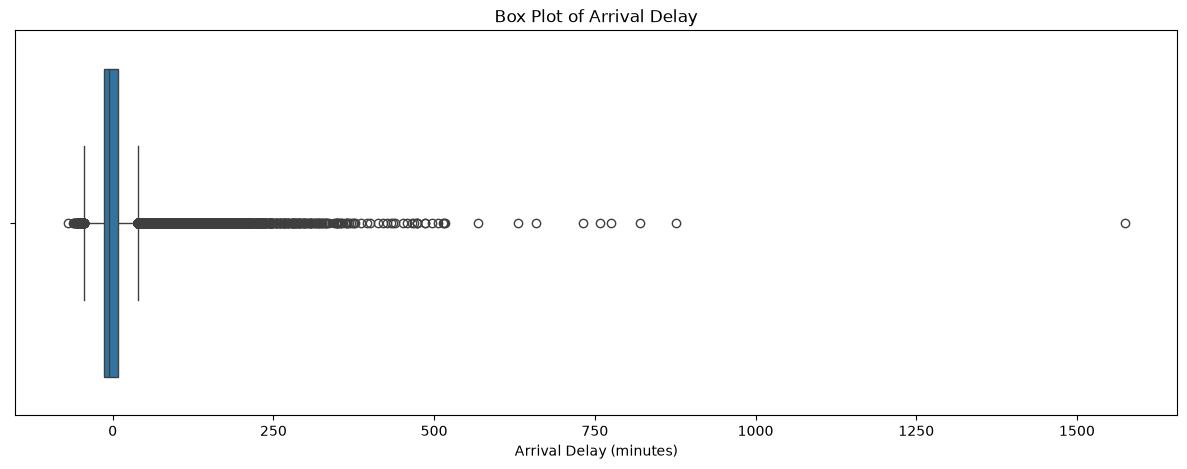

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15,5))

sns.boxplot(x=df["ARRIVAL_DELAY"])

plt.title("Box Plot of Arrival Delay")
plt.xlabel("Arrival Delay (minutes)")
plt.show()

In [35]:
Q1 = df["ARRIVAL_DELAY"].quantile(0.25)
Q3 = df["ARRIVAL_DELAY"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -44.5
Upper Bound: 39.5


In [36]:
outliers = df[
    (df["ARRIVAL_DELAY"] < lower_bound) |
    (df["ARRIVAL_DELAY"] > upper_bound)
]

print("Number of Outliers:", len(outliers))

outliers.head()

Number of Outliers: 4317


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
43,2015,1,16,5,AS,302,N708AS,SEA,SFO,1755,...,2113.0,75.0,0,0,NaN,75.0,0.0,0.0,0.0,0.0
51,2015,11,22,7,UA,1530,N69847,EWR,CLE,1554,...,1810.0,41.0,0,0,NaN,0.0,0.0,0.0,41.0,0.0
58,2015,3,23,1,EV,6138,N12552,ORD,OKC,910,...,1757.0,386.0,0,0,NaN,4.0,0.0,4.0,6.0,372.0
59,2015,1,12,1,MQ,3450,N925MQ,MAF,DFW,1435,...,1737.0,112.0,0,0,NaN,22.0,0.0,46.0,44.0,0.0
80,2015,3,20,5,US,729,N664AW,PHL,SEA,1800,...,2233.0,80.0,0,0,NaN,80.0,0.0,0.0,0.0,0.0


### now let find the outliers for all the num col

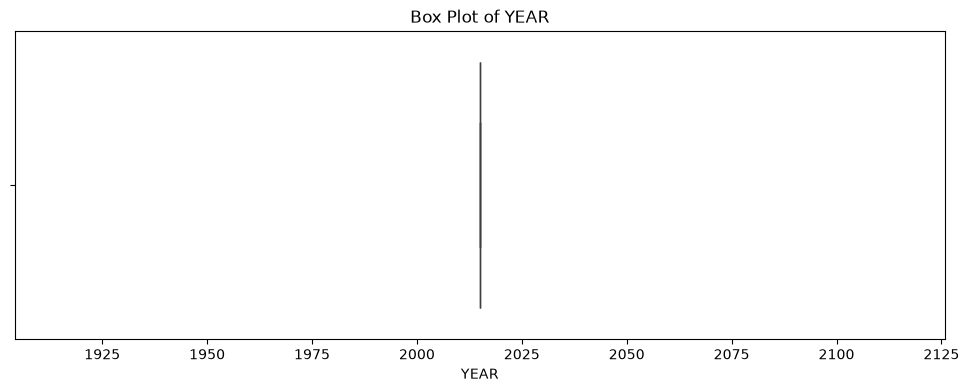

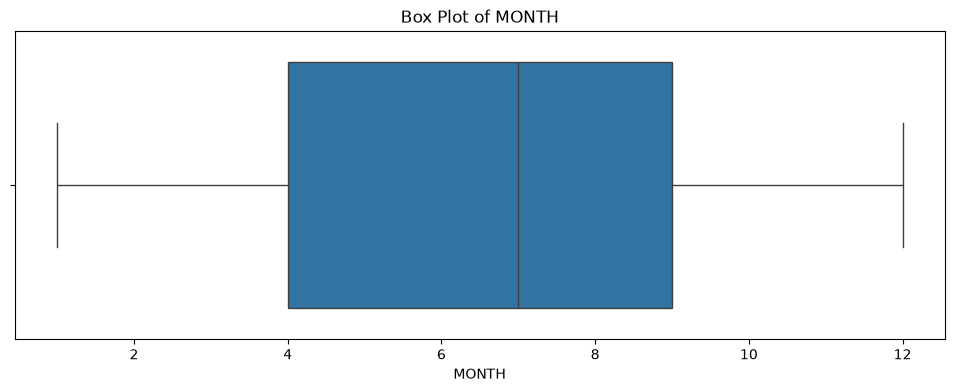

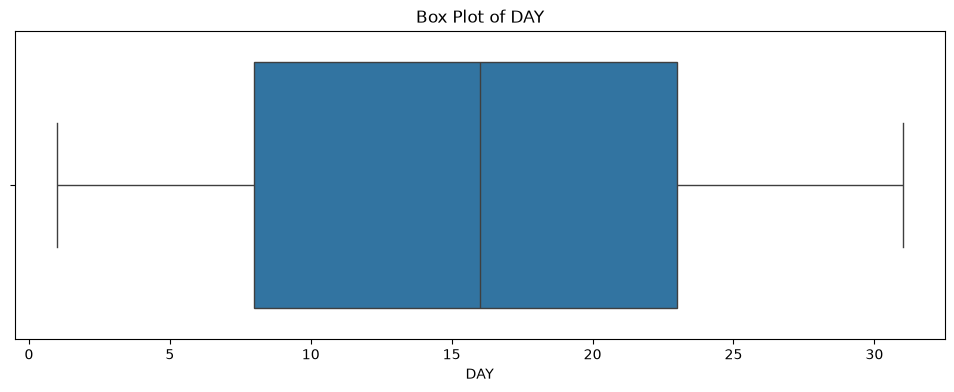

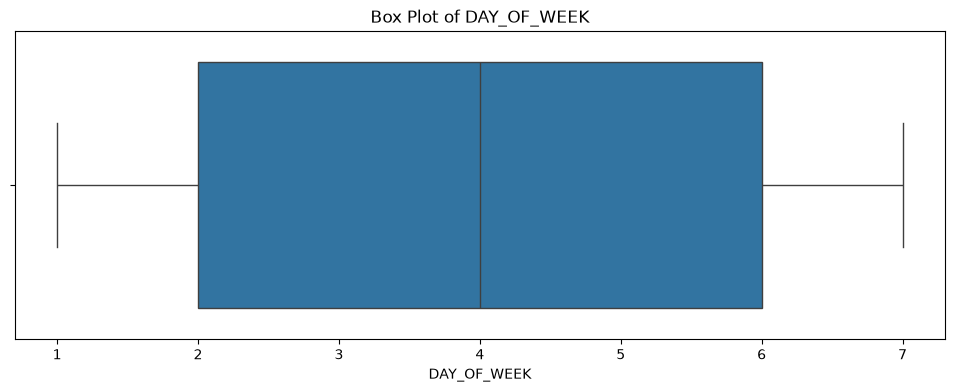

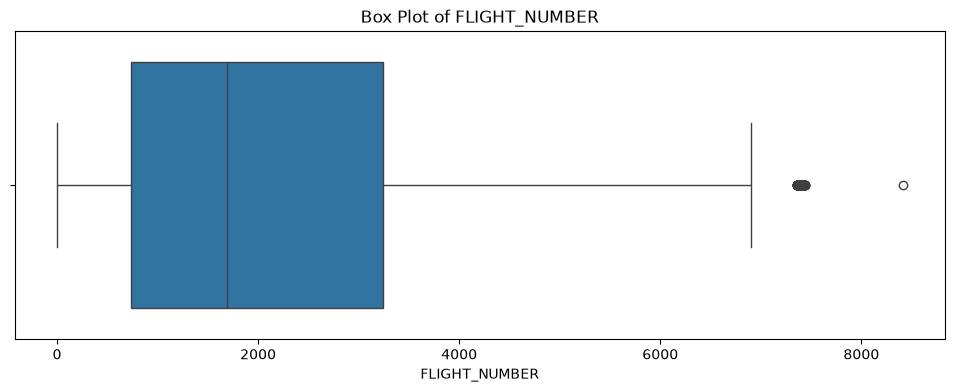

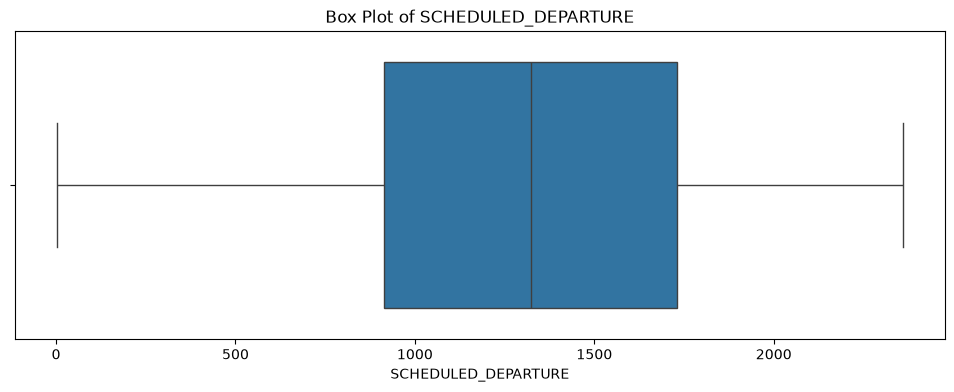

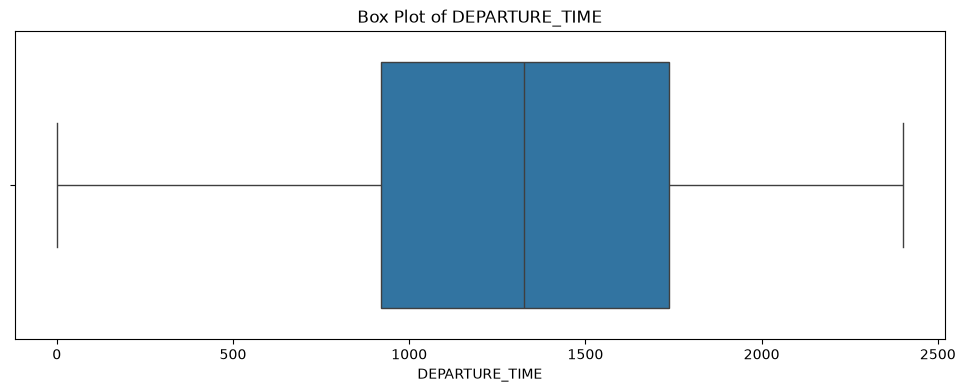

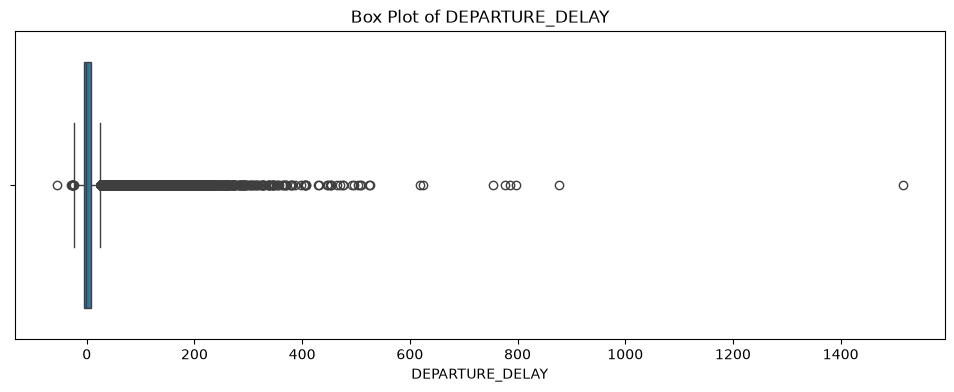

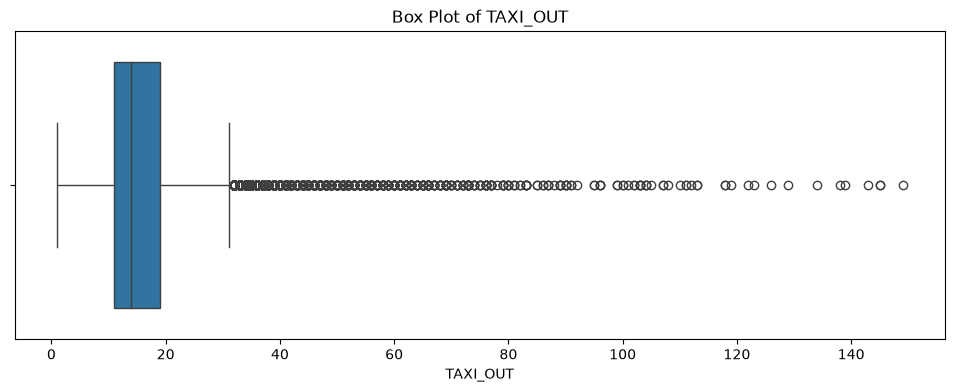

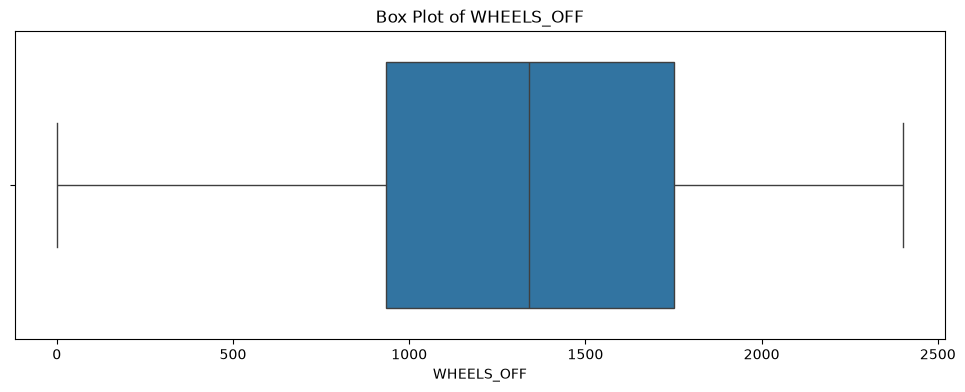

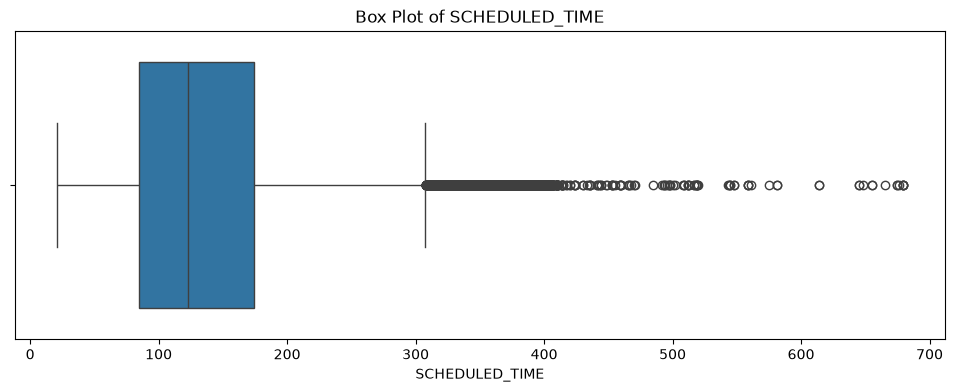

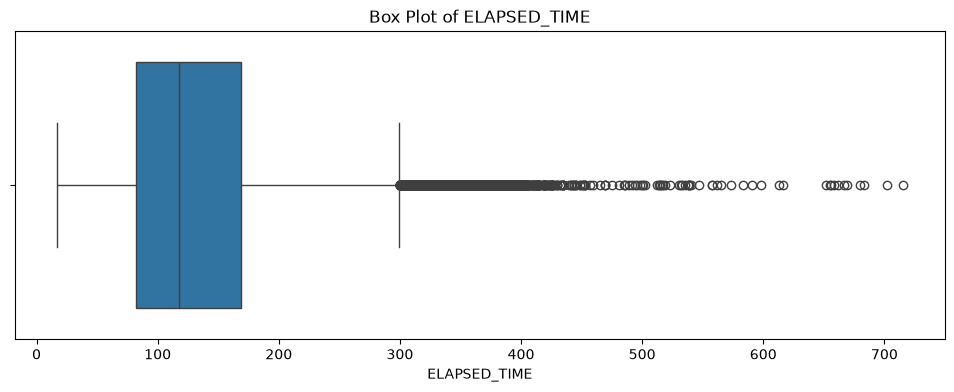

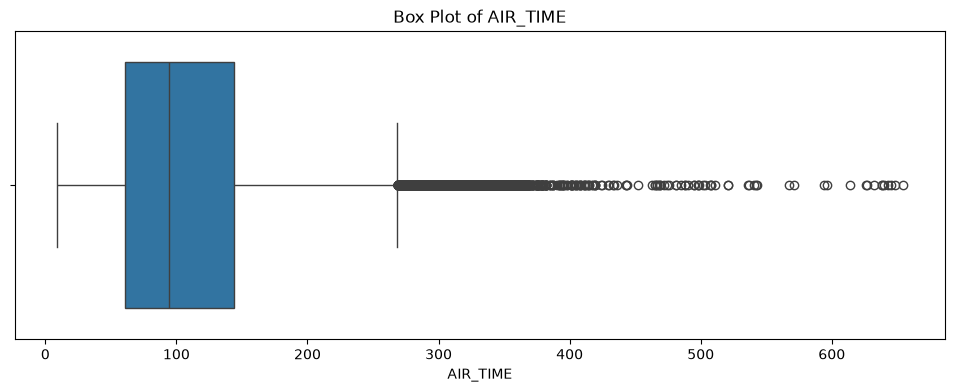

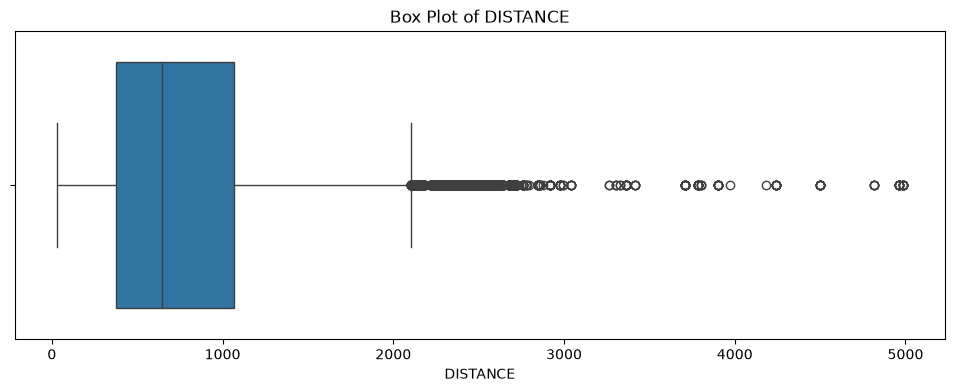

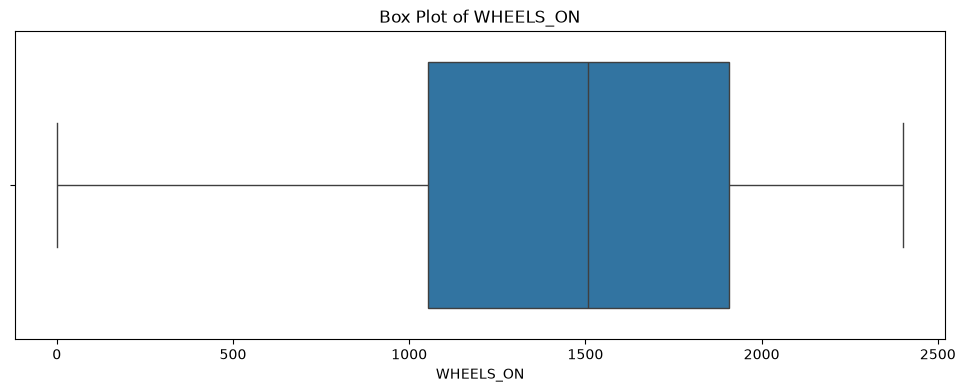

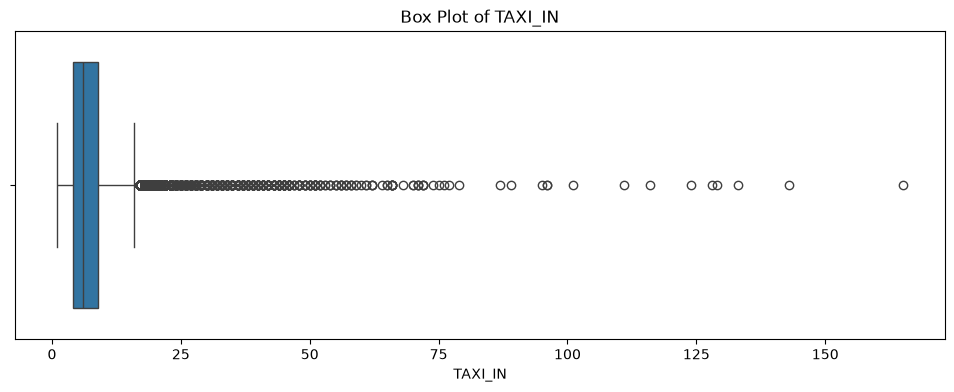

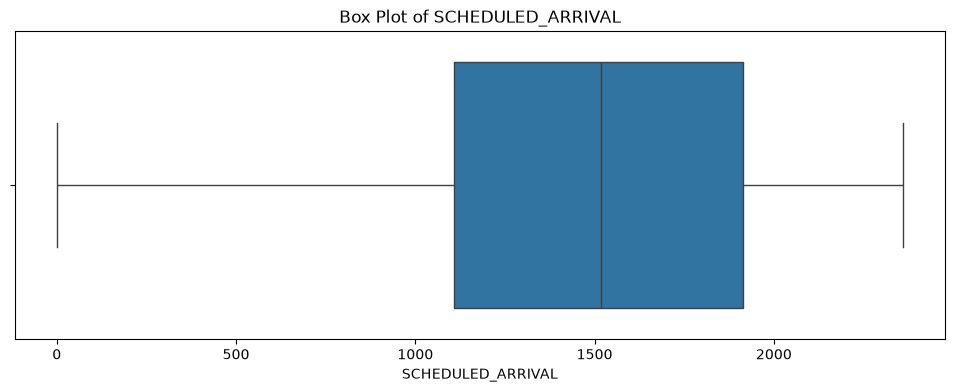

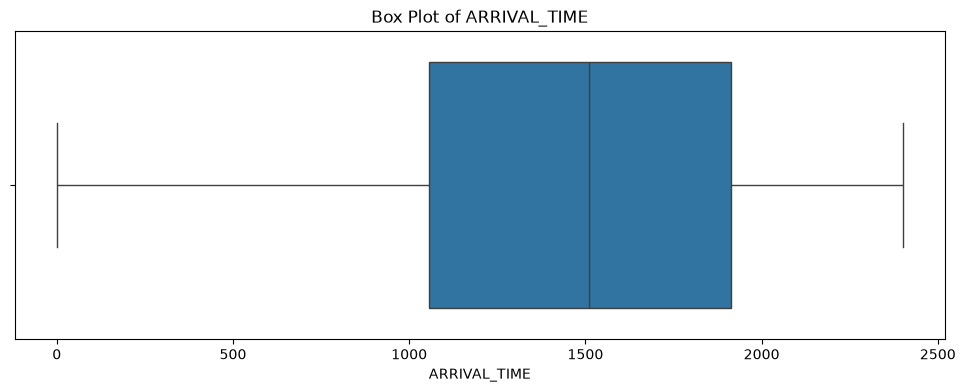

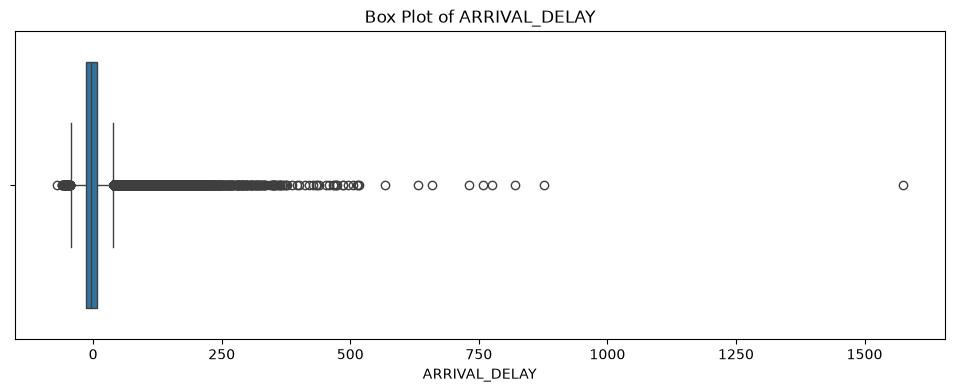

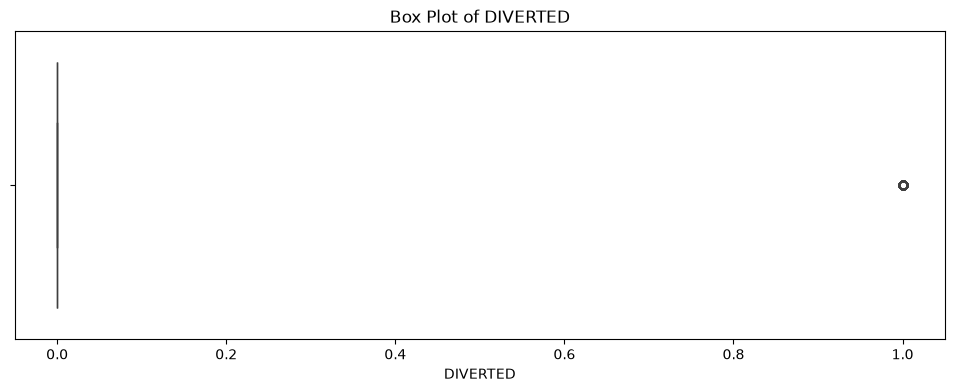

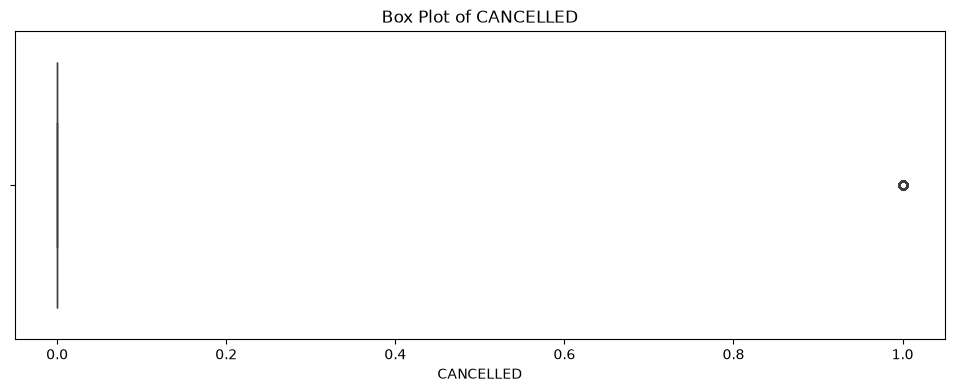

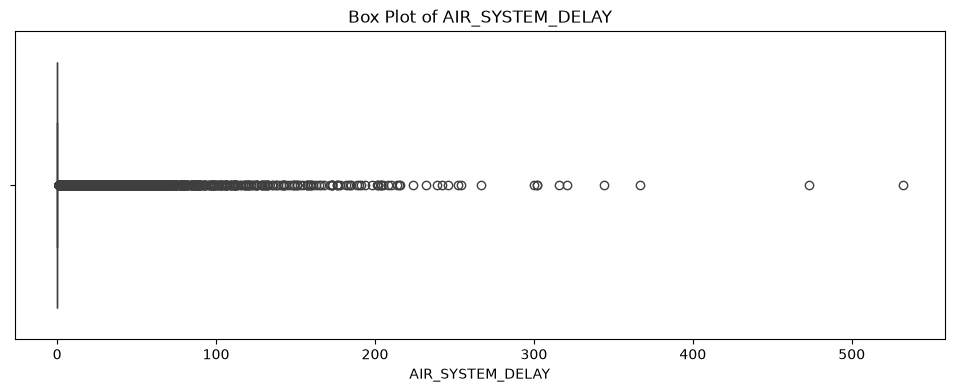

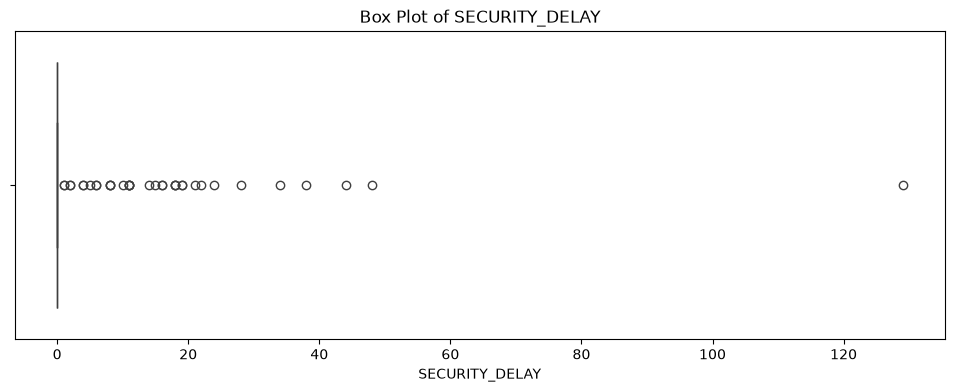

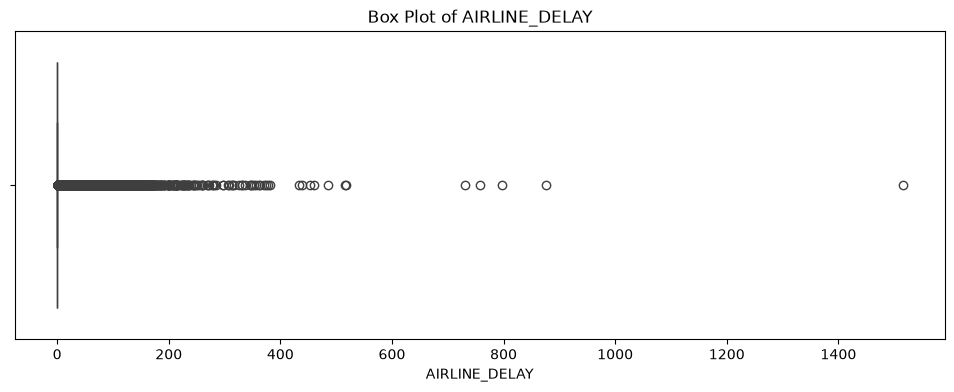

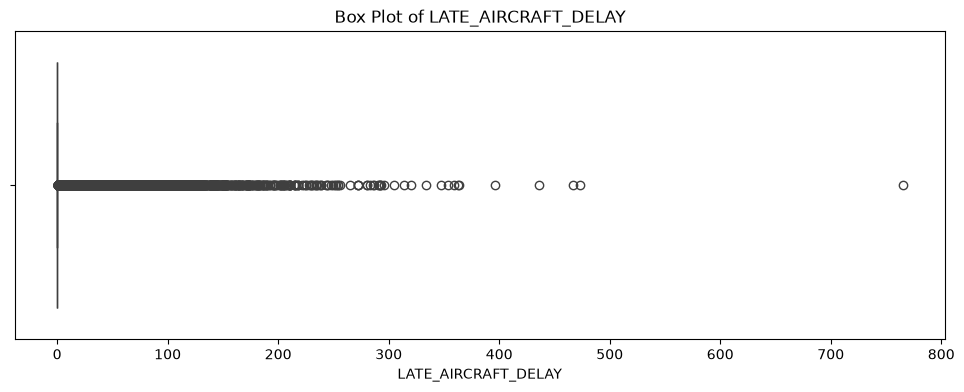

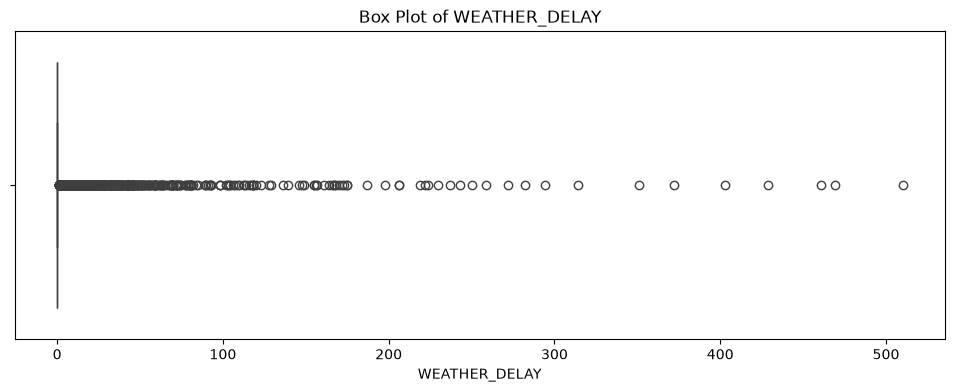

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in num_col:

    plt.figure(figsize=(12,4))

    sns.boxplot(x=df[col])

    plt.title(f"Box Plot of {col}")

    plt.show()

In [38]:
outlier_summary = []

for col in num_col:

    Q1 = df[col].quantile(0.25)

    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - (1.5 * IQR)

    upper = Q3 + (1.5 * IQR)

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    outlier_summary.append({
        "Column": col,
        "Outliers": len(outliers),
        "Lower Bound": lower,
        "Upper Bound": upper
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df

,Column,Outliers,Lower Bound,Upper Bound
0,YEAR,0,2015.0,2015.0
1,MONTH,0,-3.5,16.5
2,DAY,0,-14.5,45.5
3,DAY_OF_WEEK,0,-4.0,12.0
4,FLIGHT_NUMBER,240,-3036.5,7015.5
5,SCHEDULED_DEPARTURE,0,-307.5,2952.5
6,DEPARTURE_TIME,0,-308.0,2964.0
7,DEPARTURE_DELAY,6261,-23.0,25.0
8,TAXI_OUT,2370,-1.0,31.0
9,WHEELS_OFF,0,-294.0,2978.0


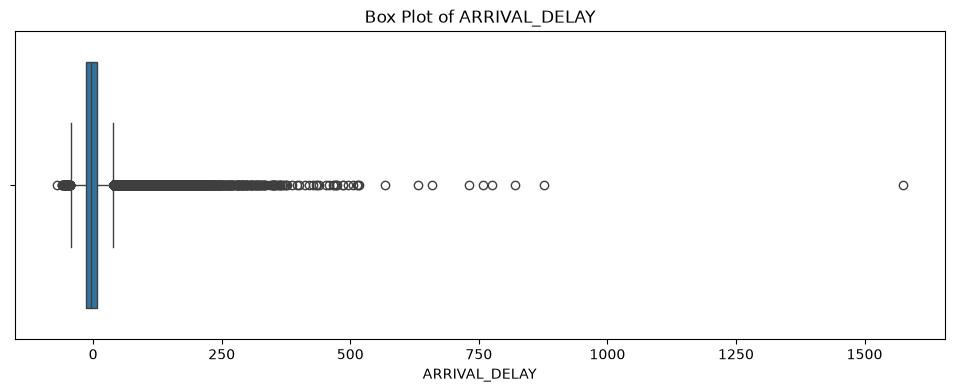

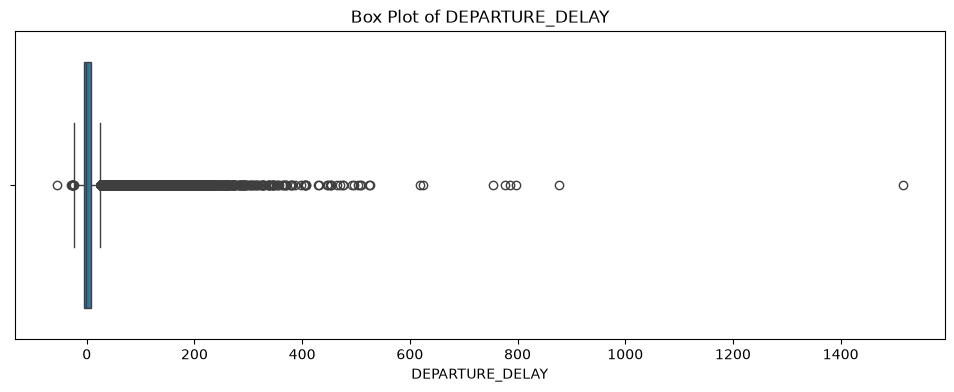

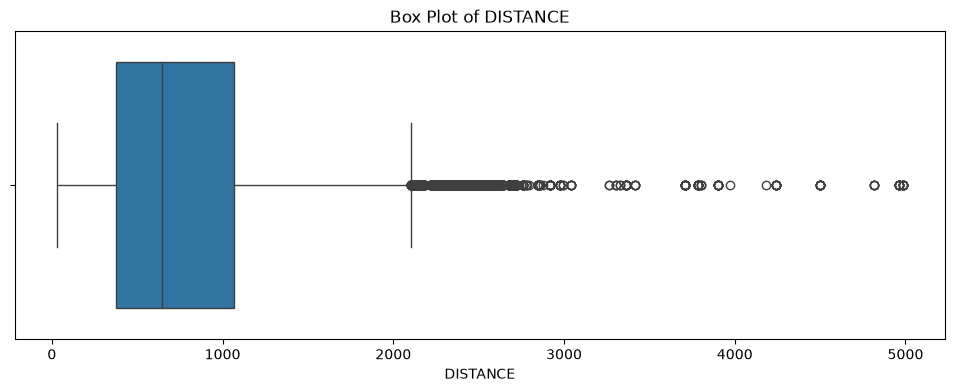

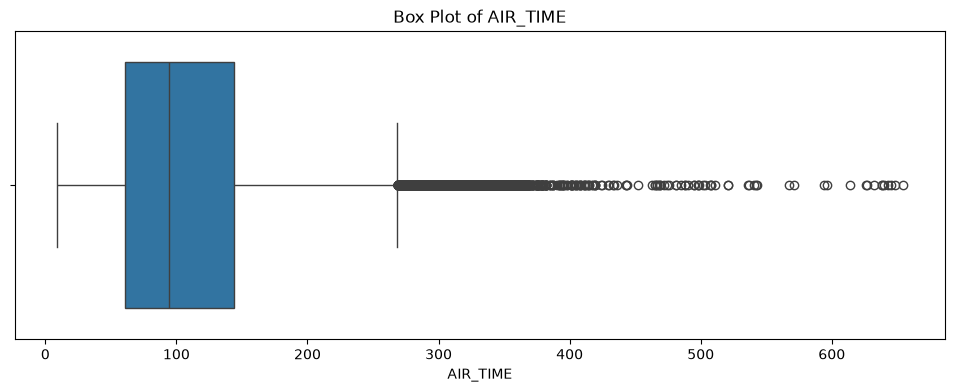

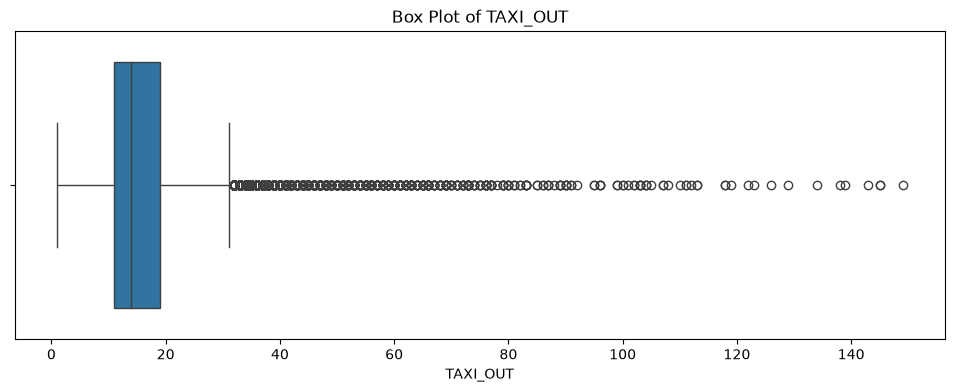

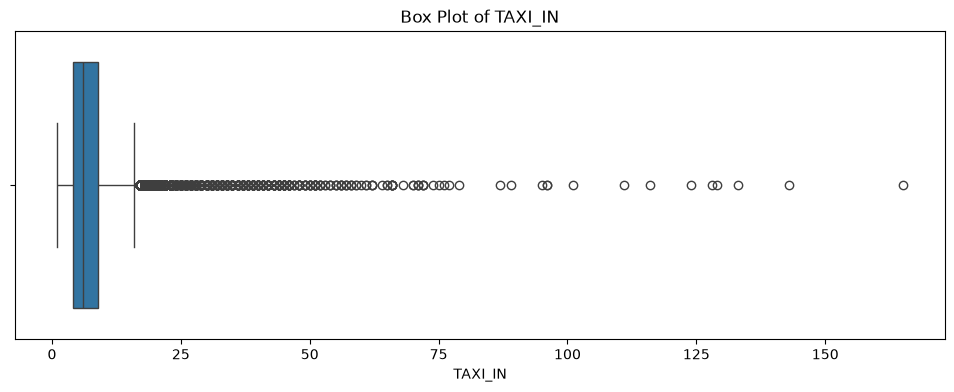

In [39]:
columns = [
    "ARRIVAL_DELAY",
    "DEPARTURE_DELAY",
    "DISTANCE",
    "AIR_TIME",
    "TAXI_OUT",
    "TAXI_IN"
]

for col in columns:
    plt.figure(figsize=(12,4))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot of {col}")
    plt.show()

In [40]:
df.isnull().sum()


YEAR                       0
MONTH                      0
DAY                        0
DAY_OF_WEEK                0
AIRLINE                    0
FLIGHT_NUMBER              0
TAIL_NUMBER                0
ORIGIN_AIRPORT             0
DESTINATION_AIRPORT        0
SCHEDULED_DEPARTURE        0
DEPARTURE_TIME           766
DEPARTURE_DELAY          766
TAXI_OUT                 785
WHEELS_OFF               785
SCHEDULED_TIME             0
ELAPSED_TIME             915
AIR_TIME                 915
DISTANCE                   0
WHEELS_ON                818
TAXI_IN                  818
SCHEDULED_ARRIVAL          0
ARRIVAL_TIME             818
ARRIVAL_DELAY            915
DIVERTED                   0
CANCELLED                  0
CANCELLATION_REASON    49206
AIR_SYSTEM_DELAY           0
SECURITY_DELAY             0
AIRLINE_DELAY              0
LATE_AIRCRAFT_DELAY        0
WEATHER_DELAY              0
dtype: int64

In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
df.dtypes

YEAR                     int64
MONTH                    int64
DAY                      int64
DAY_OF_WEEK              int64
AIRLINE                    str
FLIGHT_NUMBER            int64
TAIL_NUMBER                str
ORIGIN_AIRPORT             str
DESTINATION_AIRPORT        str
SCHEDULED_DEPARTURE      int64
DEPARTURE_TIME         float64
DEPARTURE_DELAY        float64
TAXI_OUT               float64
WHEELS_OFF             float64
SCHEDULED_TIME           int64
ELAPSED_TIME           float64
AIR_TIME               float64
DISTANCE                 int64
WHEELS_ON              float64
TAXI_IN                float64
SCHEDULED_ARRIVAL        int64
ARRIVAL_TIME           float64
ARRIVAL_DELAY          float64
DIVERTED                 int64
CANCELLED                int64
CANCELLATION_REASON        str
AIR_SYSTEM_DELAY       float64
SECURITY_DELAY         float64
AIRLINE_DELAY          float64
LATE_AIRCRAFT_DELAY    float64
WEATHER_DELAY          float64
dtype: object

In [43]:
df.shape

(50000, 31)

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 50000 non-null  int64  
 1   MONTH                50000 non-null  int64  
 2   DAY                  50000 non-null  int64  
 3   DAY_OF_WEEK          50000 non-null  int64  
 4   AIRLINE              50000 non-null  str    
 5   FLIGHT_NUMBER        50000 non-null  int64  
 6   TAIL_NUMBER          50000 non-null  str    
 7   ORIGIN_AIRPORT       50000 non-null  str    
 8   DESTINATION_AIRPORT  50000 non-null  str    
 9   SCHEDULED_DEPARTURE  50000 non-null  int64  
 10  DEPARTURE_TIME       49234 non-null  float64
 11  DEPARTURE_DELAY      49234 non-null  float64
 12  TAXI_OUT             49215 non-null  float64
 13  WHEELS_OFF           49215 non-null  float64
 14  SCHEDULED_TIME       50000 non-null  int64  
 15  ELAPSED_TIME         49085 non-null  float64
 1

## Initial Business Observations

- The dataset contains detailed flight information including scheduled and actual departure/arrival times, departure and arrival delays, taxi-in and taxi-out times, air time, distance, cancellations, diversions, and different causes of delays. From the initial data inspection, flight delays appear to be an important operational factor, with multiple variables available to understand their possible causes. The presence of cancellation and diversion records also indicates that not all flights follow the normal operational process. Therefore, further analysis is required to identify the major factors contributing to flight delays and operational disruptions.

### Sprint 2

In [45]:
import numpy as np

df['ARRIVAL_STATUS'] = np.select(
    [
        df['ARRIVAL_DELAY'] < 0,
        df['ARRIVAL_DELAY'] > 0,
        df['ARRIVAL_DELAY'] == 0
    ],
    [
        'Early',
        'Delayed',
        'On Time'
    ],
    default='Missing'
)

In [46]:
df['ARRIVAL_STATUS'].value_counts()

ARRIVAL_STATUS
Early      30181
Delayed    17858
On Time     1046
Missing      915
Name: count, dtype: int64

In [47]:
status_percentage = df['ARRIVAL_STATUS'].value_counts(normalize=True) * 100

status_percentage.round(2)

ARRIVAL_STATUS
Early      60.36
Delayed    35.72
On Time     2.09
Missing     1.83
Name: proportion, dtype: float64

The arrival status analysis shows that 60.36% of flights arrived earlier than their scheduled arrival time, while 35.72% experienced arrival delays. Only 2.09% arrived exactly on schedule, and 1.83% of records had missing arrival-delay information. This indicates that arrival delays affect a considerable proportion of flights and require further investigation to identify the contributing operational factors.

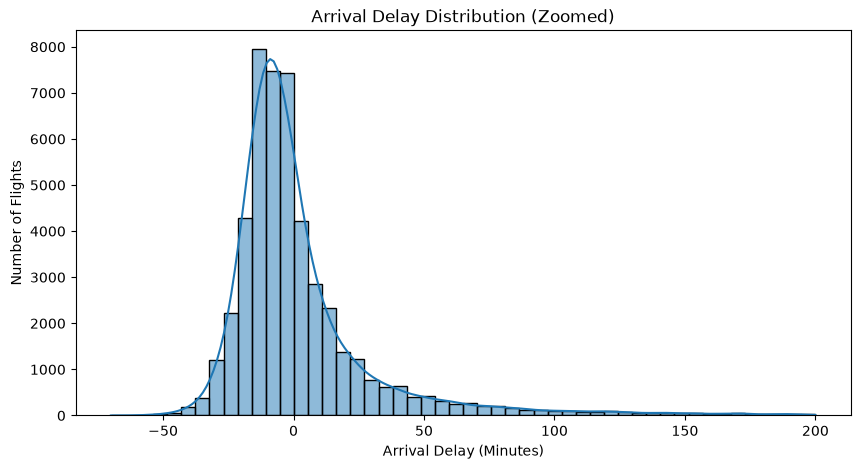

In [49]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df['ARRIVAL_DELAY'].between(-75, 200)],
    x='ARRIVAL_DELAY',
    bins=50,
    kde=True
)

plt.title('Arrival Delay Distribution (Zoomed)')
plt.xlabel('Arrival Delay (Minutes)')
plt.ylabel('Number of Flights')
plt.show()

In [50]:
airline_analysis = df.groupby('AIRLINE').agg(
    total_flights=('ARRIVAL_DELAY', 'count'),
    avg_arrival_delay=('ARRIVAL_DELAY', 'mean'),
    median_arrival_delay=('ARRIVAL_DELAY', 'median'),
    delayed_flights=('ARRIVAL_DELAY', lambda x: (x > 0).sum()),
    delayed_percentage=('ARRIVAL_DELAY', lambda x: (x > 0).mean() * 100)
)

airline_analysis = airline_analysis.sort_values(
    by='avg_arrival_delay',
    ascending=False
)

airline_analysis.round(2)

,total_flights,avg_arrival_delay,median_arrival_delay,delayed_flights,delayed_percentage
AIRLINE,,,,,
NK,977,14.51,2.0,526,53.13
F9,741,10.40,-3.0,314,41.87
VX,537,7.04,-3.0,214,39.63
EV,4802,6.51,-4.0,1863,37.49
MQ,2423,6.50,-6.0,908,35.48
B6,2274,5.86,-5.0,864,37.26
OO,4884,5.10,-4.0,1854,37.13
WN,10796,4.39,-4.0,4082,37.29
UA,4277,4.34,-6.0,1533,35.29


- NK: Has both the highest average arrival delay and the highest percentage of delayed flights.
- F9: Has the second-highest average delay at 10.40 minutes.
- AS: Has the lowest average delay, at -1.17 minutes, indicating that its flights arrived early on average.
- DL: Has the lowest percentage of delayed flights, at 29.19%.
- HA: Its average delay is only 1.08 minutes, but 39.82% of its flights were delayed. This shows why average delay and delayed-flight percentage measure different things.

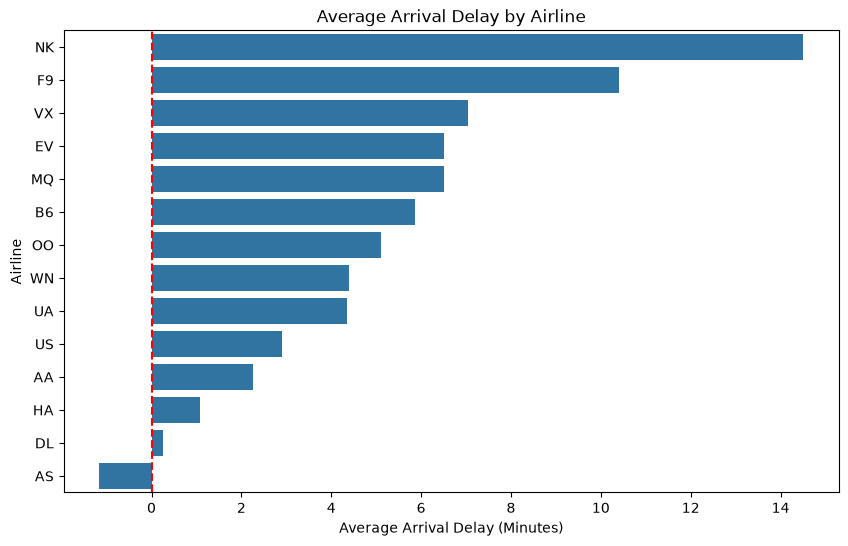

In [51]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=airline_analysis.reset_index(),
    x='avg_arrival_delay',
    y='AIRLINE'
)

plt.axvline(x=0, color='red', linestyle='--')

plt.title('Average Arrival Delay by Airline')
plt.xlabel('Average Arrival Delay (Minutes)')
plt.ylabel('Airline')

plt.show()

- NK has the highest average arrival delay, approximately 14.5 minutes.
- F9 comes second, with approximately 10.4 minutes.
- VX, EV and MQ also show relatively higher average delays.
- DL is close to zero, indicating flights generally arrive close to schedule on average.
- AS is the only airline with a negative average delay, meaning its flights arrive early on average.

In [52]:
monthly_analysis = df.groupby('MONTH').agg(
    total_flights=('ARRIVAL_DELAY', 'count'),
    avg_arrival_delay=('ARRIVAL_DELAY', 'mean'),
    median_arrival_delay=('ARRIVAL_DELAY', 'median'),
    delayed_flights=('ARRIVAL_DELAY', lambda x: (x > 0).sum())
)

monthly_analysis['delayed_percentage'] = (
    monthly_analysis['delayed_flights'] /
    monthly_analysis['total_flights'] * 100
)

monthly_analysis.round(2)

,total_flights,avg_arrival_delay,median_arrival_delay,delayed_flights,delayed_percentage
MONTH,,,,,
1,3845,5.76,-4.0,1534,39.90
2,3461,9.77,-2.0,1498,43.28
3,4203,4.05,-4.0,1595,37.95
4,4149,2.47,-5.0,1424,34.32
5,4169,2.85,-5.0,1457,34.95
6,4317,9.48,-3.0,1860,43.09
7,4388,5.74,-4.0,1712,39.02
8,4360,4.26,-5.0,1562,35.83
9,3972,-0.57,-7.0,1158,29.15


- February has the highest average delay and delayed-flight percentage.
- June also shows a high delay percentage, almost equal to February.
- September and October have the lowest delayed-flight percentages.
- September and October have negative average delays, meaning flights arrived early on average.
- December shows an increase in average delays compared with October and November.

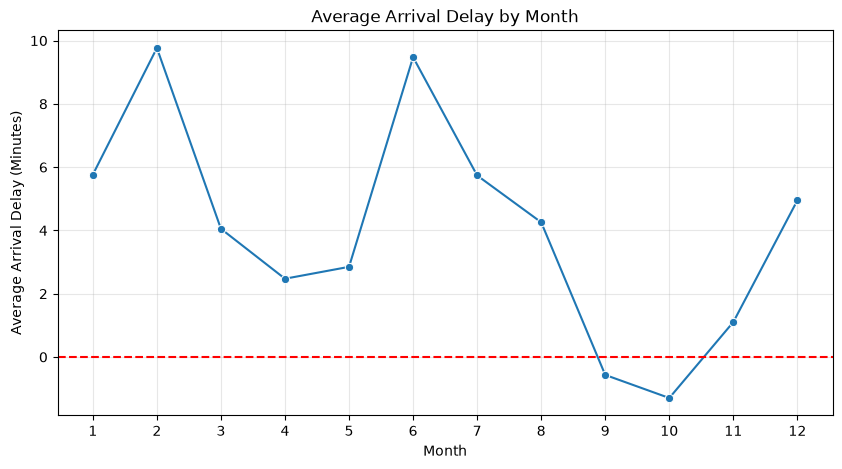

In [53]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_analysis,
    x=monthly_analysis.index,
    y='avg_arrival_delay',
    marker='o'
)

plt.axhline(y=0, color='red', linestyle='--')

plt.title('Average Arrival Delay by Month')
plt.xlabel('Month')
plt.ylabel('Average Arrival Delay (Minutes)')
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)

plt.show()

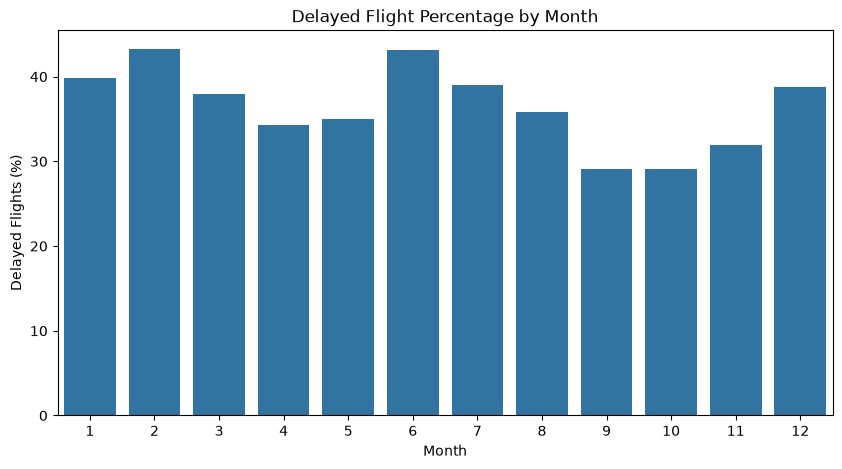

In [54]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_analysis.index,
    y=monthly_analysis['delayed_percentage']
)

plt.title('Delayed Flight Percentage by Month')
plt.xlabel('Month')
plt.ylabel('Delayed Flights (%)')
plt.show()

In [55]:
day_analysis = df.groupby('DAY_OF_WEEK').agg(
    total_flights=('ARRIVAL_DELAY', 'count'),
    avg_arrival_delay=('ARRIVAL_DELAY', 'mean'),
    median_arrival_delay=('ARRIVAL_DELAY', 'median'),
    delayed_flights=('ARRIVAL_DELAY', lambda x: (x > 0).sum())
)

day_analysis['delayed_percentage'] = (
    day_analysis['delayed_flights'] /
    day_analysis['total_flights'] * 100
)

day_analysis.round(2)

,total_flights,avg_arrival_delay,median_arrival_delay,delayed_flights,delayed_percentage
DAY_OF_WEEK,,,,,
1,7196,5.42,-5.0,2720,37.80
2,7002,3.82,-5.0,2536,36.22
3,7126,3.09,-5.0,2496,35.03
4,7562,5.44,-4.0,2928,38.72
5,7200,4.83,-4.0,2778,38.58
6,5969,1.11,-7.0,1914,32.07
7,7030,3.71,-5.0,2486,35.36


- Thursday has the highest delayed-flight percentage at 38.72%.
- Friday is close behind at 38.58%.
- Saturday has the lowest delayed-flight percentage at 32.07%.
- Thursday also has the highest average arrival delay.
- Saturday has the lowest average delay, at 1.11 minutes.
- All seven days have negative median arrival delays, indicating that the median flight arrived early.

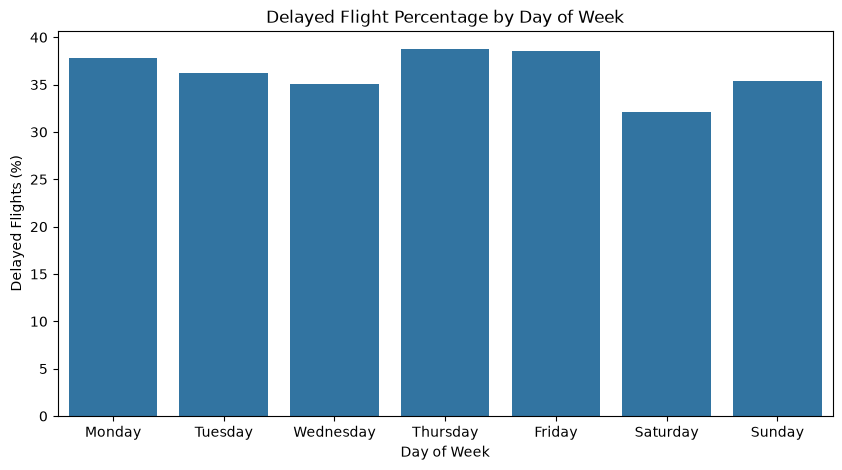

In [57]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=day_analysis.index,
    y=day_analysis['delayed_percentage']
)

plt.title('Delayed Flight Percentage by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Delayed Flights (%)')

plt.xticks(
    ticks=range(7),
    labels=['Monday', 'Tuesday', 'Wednesday',
            'Thursday', 'Friday', 'Saturday', 'Sunday']
)

plt.show()

- Thursday: Highest delayed-flight percentage (38.72%).
- Friday: Second highest (38.58%).
- Saturday: Lowest (32.07%).
- Wednesday: Relatively low delay percentage (35.03%).
- Delayed-flight percentages are relatively higher towards the end of the working week.

In [58]:
destination_analysis = df.groupby('DESTINATION_AIRPORT').agg(
    total_flights=('ARRIVAL_DELAY', 'count'),
    avg_arrival_delay=('ARRIVAL_DELAY', 'mean'),
    median_arrival_delay=('ARRIVAL_DELAY', 'median'),
    delayed_flights=('ARRIVAL_DELAY', lambda x: (x > 0).sum())
)

destination_analysis['delayed_percentage'] = (
    destination_analysis['delayed_flights'] /
    destination_analysis['total_flights'] * 100
)

destination_analysis.round(2)

,total_flights,avg_arrival_delay,median_arrival_delay,delayed_flights,delayed_percentage
DESTINATION_AIRPORT,,,,,
10136,4,-4.00,-7.5,1,25.00
10140,14,1.07,-1.0,7,50.00
10141,2,3.50,3.5,1,50.00
10146,1,-14.00,-14.0,0,0.00
10155,2,0.00,0.0,1,50.00
...,...,...,...,...,...
WRG,5,-12.40,-10.0,0,0.00
WYS,2,5.00,5.0,2,100.00
XNA,77,3.04,-3.0,33,42.86


In [59]:
destination_filtered = destination_analysis[
    destination_analysis['total_flights'] >= 100
]

In [60]:
top_10_delayed_airports = destination_filtered.sort_values(
    by='avg_arrival_delay',
    ascending=False
).head(10)

top_10_delayed_airports.round(2)

,total_flights,avg_arrival_delay,median_arrival_delay,delayed_flights,delayed_percentage
DESTINATION_AIRPORT,,,,,
BHM,132,10.57,-4.0,51,38.64
GRR,108,10.04,-3.5,36,33.33
RIC,135,9.99,-4.0,57,42.22
BUF,149,9.85,-6.0,56,37.58
LGA,801,8.63,-4.0,340,42.45
RSW,210,7.80,-7.0,68,32.38
BDL,163,7.61,-3.0,68,41.72
CMH,184,7.52,-3.0,80,43.48
BOI,107,6.98,-4.0,45,42.06


- BHM has the highest average arrival delay among the selected airports.

- CMH has the highest delayed-flight percentage, despite not having the highest average delay.

- LAX has the largest number of flights among these ten airports.

- LGA also has a relatively high delayed-flight percentage of 42.45%.

- All ten airports have negative median delays, meaning their median arrival delay is early, despite positive average delays.

In [61]:
bottom_10_airports = destination_filtered.sort_values(
    by='avg_arrival_delay',
    ascending=True
).head(10)

bottom_10_airports.round(2)

,total_flights,avg_arrival_delay,median_arrival_delay,delayed_flights,delayed_percentage
DESTINATION_AIRPORT,,,,,
12889,101,-3.53,-6.0,24,23.76
10397,271,-3.48,-8.0,58,21.40
13930,248,-2.40,-8.0,69,27.82
14771,141,-1.89,-9.0,34,24.11
SLC,830,-1.60,-7.0,237,28.55
11298,182,-0.44,-10.0,49,26.92
PDX,412,-0.22,-6.5,124,30.10
12892,153,0.69,-7.0,48,31.37
ANC,147,0.83,-4.0,59,40.14


In [67]:

origin_analysis = df.groupby('ORIGIN_AIRPORT').agg(
    total_flights=('DEPARTURE_DELAY', 'count'),
    avg_departure_delay=('DEPARTURE_DELAY', 'mean'),
    median_departure_delay=('DEPARTURE_DELAY', 'median'),
    delayed_flights=('DEPARTURE_DELAY', lambda x: (x > 0).sum())
)

origin_analysis['delayed_percentage'] = (
    origin_analysis['delayed_flights'] /
    origin_analysis['total_flights'] * 100
)

origin_analysis = origin_analysis.round(2)

origin_analysis.head()


,total_flights,avg_departure_delay,median_departure_delay,delayed_flights,delayed_percentage
ORIGIN_AIRPORT,,,,,
10135,1,0.00,0.0,0,0.00
10140,16,5.75,1.5,8,50.00
10155,3,-6.33,-8.0,1,33.33
10157,3,6.00,4.0,2,66.67
10158,1,-9.00,-9.0,0,0.00


In [68]:

origin_filtered = origin_analysis[
    origin_analysis['total_flights'] >= 100
]

top_10_origin_airports = origin_filtered.sort_values(
    by='avg_departure_delay',
    ascending=False
).head(10)

top_10_origin_airports


,total_flights,avg_departure_delay,median_departure_delay,delayed_flights,delayed_percentage
ORIGIN_AIRPORT,,,,,
BWI,772,15.86,2.0,427,55.31
IAD,276,15.43,0.0,125,45.29
ORD,2419,13.89,-1.0,1055,43.61
TUL,108,13.86,-2.5,42,38.89
EWR,858,13.77,0.0,400,46.62
LGA,819,13.10,-2.0,308,37.61
FLL,619,12.60,-2.0,219,35.38
DEN,1630,12.48,0.0,738,45.28
LAS,1130,12.33,0.0,502,44.42


- BWI has the highest average departure delay (15.86 minutes) and the highest delayed-flight percentage (55.31%) among these airports.



- ORD has the largest flight volume (2,419 flights) among the top 10, making its delays operationally significant.



- IAD has the second-highest average delay (15.43 minutes).



- EWR, DEN and LAS also have relatively high delayed-flight percentages.



- These results suggest that departure delays are concentrated at certain airports, but further analysis is needed to understand the reasons.

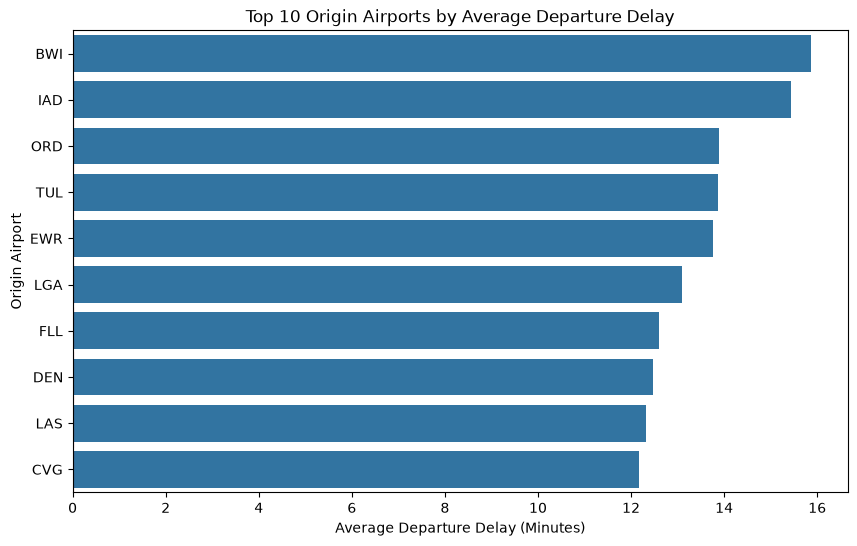

In [69]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_origin_airports.reset_index(),
    x='avg_departure_delay',
    y='ORIGIN_AIRPORT'
)

plt.axvline(0, color='red', linestyle='--')
plt.title('Top 10 Origin Airports by Average Departure Delay')
plt.xlabel('Average Departure Delay (Minutes)')
plt.ylabel('Origin Airport')

plt.show()


In [70]:

delay_data = df[
    ['DEPARTURE_DELAY', 'ARRIVAL_DELAY']
].dropna()

correlation = delay_data[
    'DEPARTURE_DELAY'
].corr(delay_data['ARRIVAL_DELAY'])

print("Correlation:", round(correlation, 3))


Correlation: 0.941


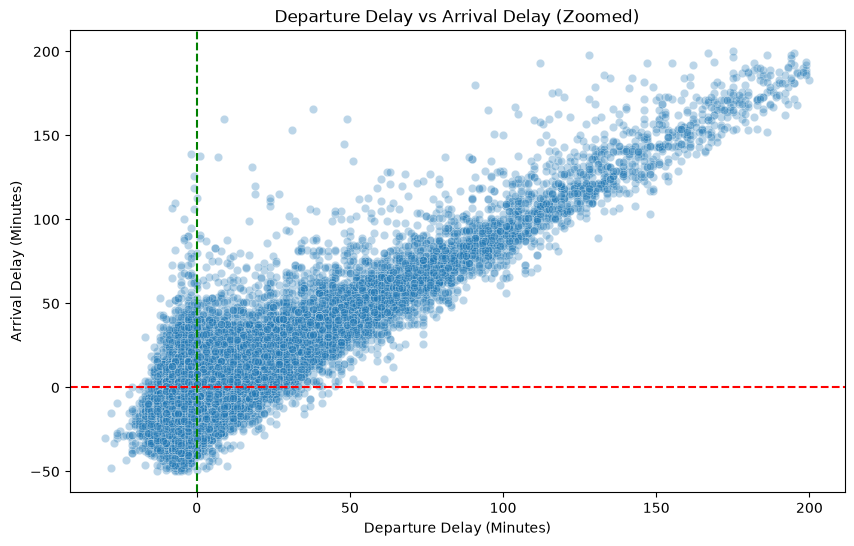

In [72]:

zoom_data = delay_data[
    delay_data['DEPARTURE_DELAY'].between(-50, 200) &
    delay_data['ARRIVAL_DELAY'].between(-50, 200)
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=zoom_data,
    x='DEPARTURE_DELAY',
    y='ARRIVAL_DELAY',
    alpha=0.3
)

plt.title('Departure Delay vs Arrival Delay (Zoomed)')
plt.xlabel('Departure Delay (Minutes)')
plt.ylabel('Arrival Delay (Minutes)')

plt.axhline(0, color='red', linestyle='--')
plt.axvline(0, color='green', linestyle='--')

plt.show()


- Strong positive pattern: As departure delay increases, arrival delay generally increases.



- Most flights: A large concentration of flights has departure and arrival delays below 50 minutes.



- Delay recovery: Some flights have a lower arrival delay than departure delay. This indicates that they recovered some time during the journey.



- High delays: Flights departing 100–200 minutes late generally also show substantial arrival delays.

In [73]:
print("Correlation:", round(correlation, 3))

Correlation: 0.941


In [75]:

airline_delay_comparison = df.groupby('AIRLINE').agg(
    total_departures=('DEPARTURE_DELAY', 'count'),
    total_arrivals=('ARRIVAL_DELAY', 'count'),

    avg_departure_delay=('DEPARTURE_DELAY', 'mean'),
    avg_arrival_delay=('ARRIVAL_DELAY', 'mean'),

    delayed_departures=('DEPARTURE_DELAY', lambda x: (x > 0).sum()),
    delayed_arrivals=('ARRIVAL_DELAY', lambda x: (x > 0).sum())
)

airline_delay_comparison['departure_delayed_percentage'] = (
    airline_delay_comparison['delayed_departures'] /
    airline_delay_comparison['total_departures'] * 100
)

airline_delay_comparison['arrival_delayed_percentage'] = (
    airline_delay_comparison['delayed_arrivals'] /
    airline_delay_comparison['total_arrivals'] * 100
)

airline_delay_comparison = airline_delay_comparison.round(2)

airline_delay_comparison.sort_values(
    by='avg_arrival_delay',
    ascending=False
)


,total_departures,total_arrivals,avg_departure_delay,avg_arrival_delay,delayed_departures,delayed_arrivals,departure_delayed_percentage,arrival_delayed_percentage
AIRLINE,,,,,,,,
NK,979,977,15.51,14.51,465,526,47.50,53.84
F9,745,741,12.12,10.40,285,314,38.26,42.38
VX,538,537,11.84,7.04,227,214,42.19,39.85
EV,4827,4802,8.59,6.51,1487,1863,30.81,38.80
MQ,2434,2423,10.37,6.50,842,908,34.59,37.47
B6,2280,2274,10.76,5.86,851,864,37.32,37.99
OO,4900,4884,7.39,5.10,1446,1854,29.51,37.96
WN,10820,10796,10.67,4.39,4950,4082,45.75,37.81
UA,4291,4277,13.66,4.34,2187,1533,50.97,35.84


- NK: Has the highest average departure and arrival delays, as well as the highest arrival delayed percentage.



- UA: 50.97% of its flights depart late, but 35.84% arrive late. This suggests that some departure delays may be recovered during the journey.



- WN: Has a 45.75% delayed departure rate compared with a 37.81% delayed arrival rate.



- HA: Has only 1.08 minutes of average arrival delay, but 40.06% of its flights arrive late. This demonstrates why average delay and delayed-flight percentage should both be considered.



- DL: Has the lowest arrival delayed percentage at 29.37%.

In [77]:

cancellation_analysis = df['CANCELLED'].value_counts()

print("Cancellation Counts:")
print(cancellation_analysis)

print("\nCancellation Percentage:")
print((df['CANCELLED'].value_counts(normalize=True) * 100).round(2))


Cancellation Counts:
CANCELLED
0    49206
1      794
Name: count, dtype: int64

Cancellation Percentage:
CANCELLED
0    98.41
1     1.59
Name: proportion, dtype: float64


In [78]:

cancelled_flights = df[df['CANCELLED'] == 1]

cancellation_reasons = cancelled_flights[
    'CANCELLATION_REASON'
].value_counts()

print(cancellation_reasons)

print("\nCancellation Reason Percentage:")
print(
    (cancellation_reasons / len(cancelled_flights) * 100).round(2)
)


CANCELLATION_REASON
B    432
A    215
C    146
D      1
Name: count, dtype: int64

Cancellation Reason Percentage:
CANCELLATION_REASON
B    54.41
A    27.08
C    18.39
D     0.13
Name: count, dtype: float64


- Reason B accounts for more than half of all cancellations, making it the most frequent cancellation reason.

- These are reason codes, so we should map them to their official descriptions before writing the final business interpretation.

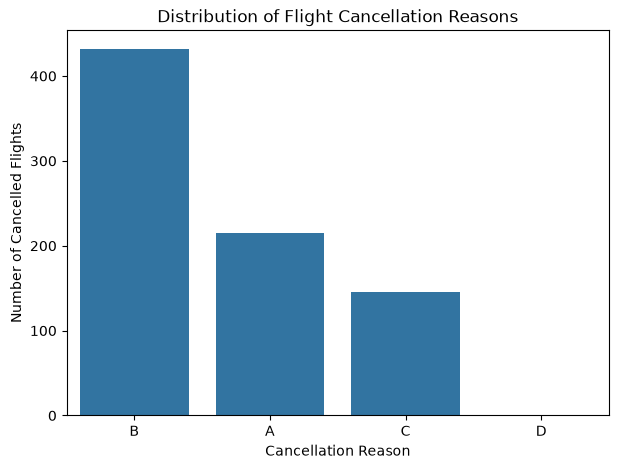

In [80]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=cancelled_flights,
    x='CANCELLATION_REASON',
    order=cancellation_reasons.index
)

plt.title('Distribution of Flight Cancellation Reasons')
plt.xlabel('Cancellation Reason')
plt.ylabel('Number of Cancelled Flights')

plt.show()


In [81]:

diversion_counts = df['DIVERTED'].value_counts()

print("Diversion Counts:")
print(diversion_counts)

print("\nDiversion Percentage:")
print(
    (df['DIVERTED'].value_counts(normalize=True) * 100).round(2)
)


Diversion Counts:
DIVERTED
0    49879
1      121
Name: count, dtype: int64

Diversion Percentage:
DIVERTED
0    99.76
1     0.24
Name: proportion, dtype: float64


In [82]:

diverted_flights = df[df['DIVERTED'] == 1]

print("Total Diverted Flights:", len(diverted_flights))

print("\nMissing Values in Diverted Flights:")
print(diverted_flights.isnull().sum())

print("\nSample Diverted Flights:")
diverted_flights.head()


Total Diverted Flights: 121

Missing Values in Diverted Flights:
YEAR                     0
MONTH                    0
DAY                      0
DAY_OF_WEEK              0
AIRLINE                  0
FLIGHT_NUMBER            0
TAIL_NUMBER              0
ORIGIN_AIRPORT           0
DESTINATION_AIRPORT      0
SCHEDULED_DEPARTURE      0
DEPARTURE_TIME           0
DEPARTURE_DELAY          0
TAXI_OUT                 0
WHEELS_OFF               0
SCHEDULED_TIME           0
ELAPSED_TIME           121
AIR_TIME               121
DISTANCE                 0
WHEELS_ON               24
TAXI_IN                 24
SCHEDULED_ARRIVAL        0
ARRIVAL_TIME            24
ARRIVAL_DELAY          121
DIVERTED                 0
CANCELLED                0
CANCELLATION_REASON    121
AIR_SYSTEM_DELAY         0
SECURITY_DELAY           0
AIRLINE_DELAY            0
LATE_AIRCRAFT_DELAY      0
WEATHER_DELAY            0
ARRIVAL_STATUS           0
dtype: int64

Sample Diverted Flights:


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,ARRIVAL_STATUS
935,2015,2,23,1,OO,5315,N983SW,JMS,DVL,1318,...,NaN,1,0,NaN,0.0,0.0,0.0,0.0,0.0,Missing
1169,2015,12,13,7,UA,1117,N418UA,MSY,IAH,639,...,NaN,1,0,NaN,0.0,0.0,0.0,0.0,0.0,Missing
1471,2015,12,26,6,AA,1398,N3CSAA,LAS,DFW,1254,...,NaN,1,0,NaN,0.0,0.0,0.0,0.0,0.0,Missing
2027,2015,5,12,2,DL,976,N3741S,LAX,TPA,1010,...,NaN,1,0,NaN,0.0,0.0,0.0,0.0,0.0,Missing
2349,2015,8,30,7,F9,676,N219FR,DEN,MCO,700,...,NaN,1,0,NaN,0.0,0.0,0.0,0.0,0.0,Missing


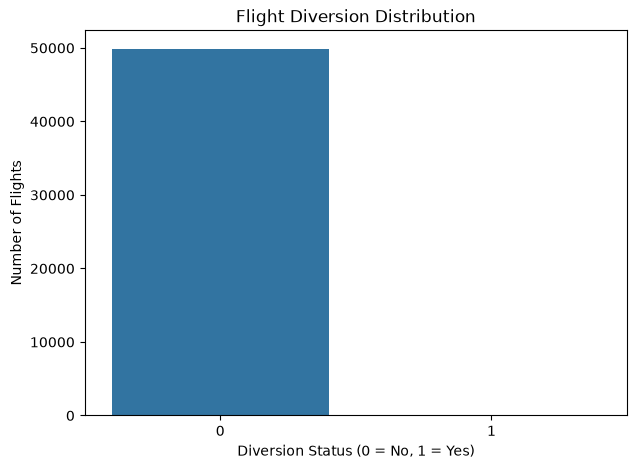

In [83]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='DIVERTED')

plt.title('Flight Diversion Distribution')
plt.xlabel('Diversion Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Flights')

plt.show()


In [84]:

delay_causes = [
    'AIR_SYSTEM_DELAY',
    'SECURITY_DELAY',
    'AIRLINE_DELAY',
    'LATE_AIRCRAFT_DELAY',
    'WEATHER_DELAY'
]

cause_analysis = df[delay_causes].sum().sort_values(
    ascending=False
)

print("Total Delay Minutes by Cause:")
print(cause_analysis)


Total Delay Minutes by Cause:
LATE_AIRCRAFT_DELAY    205967.0
AIRLINE_DELAY          167614.0
AIR_SYSTEM_DELAY       120415.0
WEATHER_DELAY           26441.0
SECURITY_DELAY            650.0
dtype: float64


In [85]:

cause_percentage = (
    cause_analysis / cause_analysis.sum()
) * 100

cause_percentage = cause_percentage.round(2)

print("Delay Cause Contribution (%):")
print(cause_percentage)


Delay Cause Contribution (%):
LATE_AIRCRAFT_DELAY    39.53
AIRLINE_DELAY          32.17
AIR_SYSTEM_DELAY       23.11
WEATHER_DELAY           5.07
SECURITY_DELAY          0.12
dtype: float64


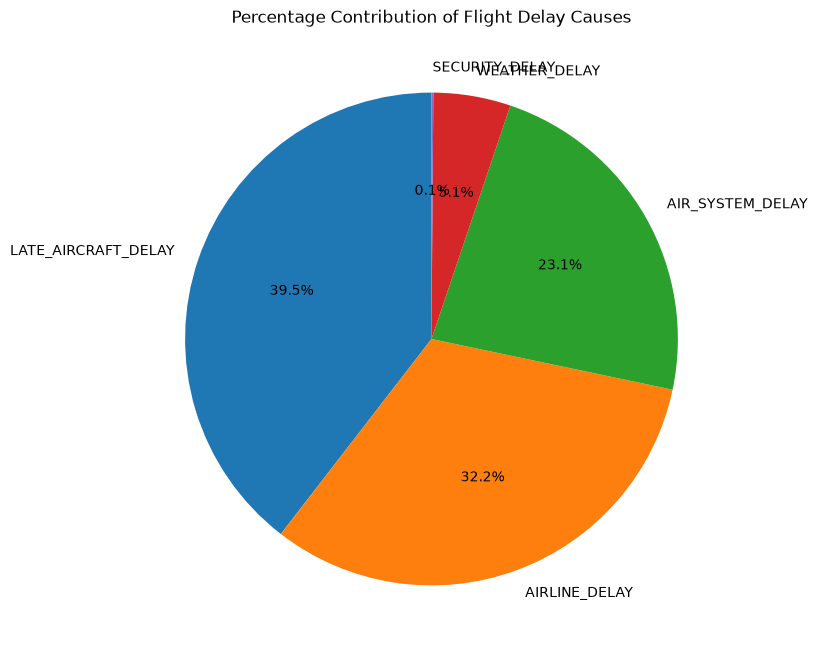

In [86]:

plt.figure(figsize=(8, 8))

plt.pie(
    cause_percentage,
    labels=cause_percentage.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage Contribution of Flight Delay Causes')

plt.show()


In [87]:

airline_cause_analysis = df.groupby('AIRLINE')[delay_causes].sum()

airline_cause_analysis


,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
AIRLINE,,,,,
AA,14178.0,240.0,22205.0,20949.0,2687.0
AS,2708.0,37.0,2680.0,3827.0,423.0
B6,8149.0,66.0,7930.0,12526.0,972.0
DL,15130.0,21.0,20648.0,19816.0,6281.0
EV,15822.0,0.0,19200.0,21231.0,2163.0
F9,4383.0,0.0,2510.0,4307.0,350.0
HA,35.0,0.0,1205.0,1235.0,127.0
MQ,8501.0,82.0,9015.0,12735.0,2778.0
NK,7810.0,26.0,4285.0,5359.0,503.0


- WN: Has the highest late aircraft delay and airline delay minutes.



- EV: Has the highest air system delay minutes.



- DL: Has the highest weather-related delay minutes.



- AA: Has the highest security-related delay minutes.



- WN's late aircraft delay is particularly significant, suggesting that aircraft turnaround and scheduling deserve further investigation.

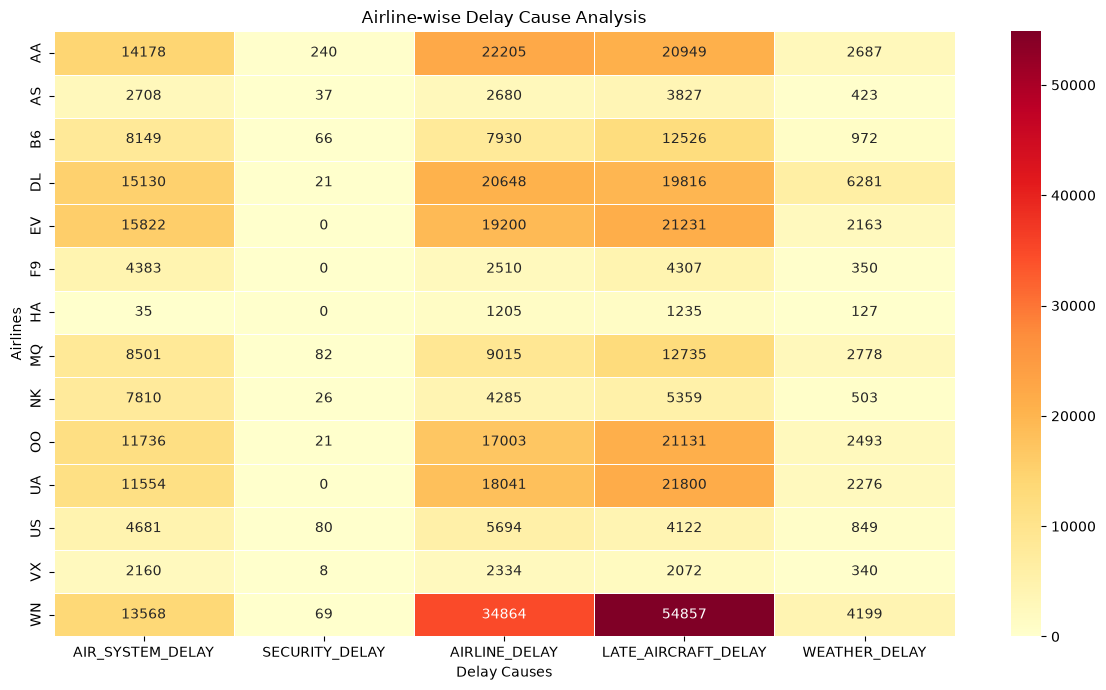

In [88]:

plt.figure(figsize=(12, 7))

sns.heatmap(
    airline_cause_analysis,
    annot=True,
    fmt='.0f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Airline-wise Delay Cause Analysis')
plt.xlabel('Delay Causes')
plt.ylabel('Airlines')
plt.tight_layout()

plt.show()


In [89]:

airline_cause_percentage = (
    airline_cause_analysis.div(
        airline_cause_analysis.sum(axis=1),
        axis=0
    ) * 100
)

airline_cause_percentage = airline_cause_percentage.round(2)

airline_cause_percentage


,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
AIRLINE,,,,,
AA,23.53,0.40,36.85,34.76,4.46
AS,27.99,0.38,27.70,39.56,4.37
B6,27.49,0.22,26.75,42.26,3.28
DL,24.44,0.03,33.36,32.01,10.15
EV,27.09,0.00,32.87,36.34,3.70
F9,37.95,0.00,21.73,37.29,3.03
HA,1.35,0.00,46.31,47.46,4.88
MQ,25.67,0.25,27.23,38.46,8.39
NK,43.43,0.14,23.83,29.80,2.80


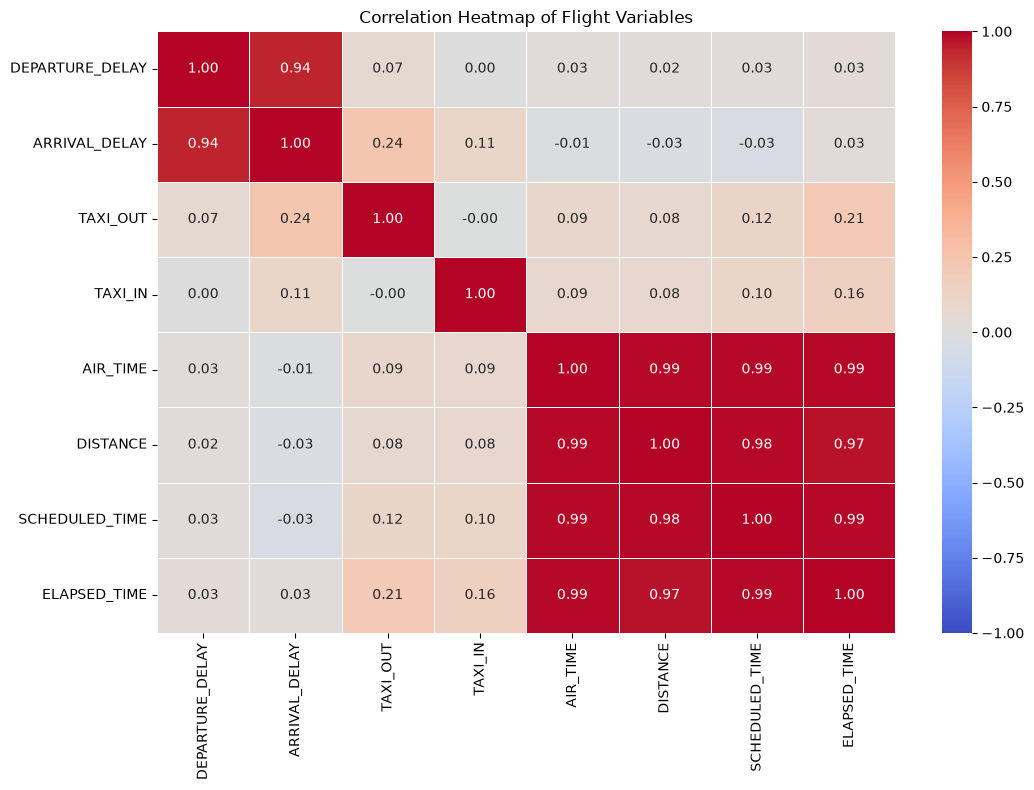

In [92]:

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_data,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation Heatmap of Flight Variables')
plt.tight_layout()

plt.show()


In [91]:

numeric_columns = [
    'DEPARTURE_DELAY',
    'ARRIVAL_DELAY',
    'TAXI_OUT',
    'TAXI_IN',
    'AIR_TIME',
    'DISTANCE',
    'SCHEDULED_TIME',
    'ELAPSED_TIME'
]

correlation_data = df[numeric_columns].corr()

correlation_data.round(2)


,DEPARTURE_DELAY,ARRIVAL_DELAY,TAXI_OUT,TAXI_IN,AIR_TIME,DISTANCE,SCHEDULED_TIME,ELAPSED_TIME
DEPARTURE_DELAY,1.00,0.94,0.07,0.00,0.03,0.02,0.03,0.03
ARRIVAL_DELAY,0.94,1.00,0.24,0.11,-0.01,-0.03,-0.03,0.03
TAXI_OUT,0.07,0.24,1.00,-0.00,0.09,0.08,0.12,0.21
TAXI_IN,0.00,0.11,-0.00,1.00,0.09,0.08,0.10,0.16
AIR_TIME,0.03,-0.01,0.09,0.09,1.00,0.99,0.99,0.99
DISTANCE,0.02,-0.03,0.08,0.08,0.99,1.00,0.98,0.97
SCHEDULED_TIME,0.03,-0.03,0.12,0.10,0.99,0.98,1.00,0.99
ELAPSED_TIME,0.03,0.03,0.21,0.16,0.99,0.97,0.99,1.00


In [93]:

df['DEPARTURE_HOUR'] = (
    df['SCHEDULED_DEPARTURE'] // 100
)

hourly_analysis = df.groupby('DEPARTURE_HOUR').agg(
    total_flights=('DEPARTURE_DELAY', 'count'),
    avg_departure_delay=('DEPARTURE_DELAY', 'mean'),
    delayed_flights=('DEPARTURE_DELAY', lambda x: (x > 0).sum())
)

hourly_analysis['delayed_percentage'] = (
    hourly_analysis['delayed_flights'] /
    hourly_analysis['total_flights'] * 100
)

hourly_analysis = hourly_analysis.round(2)

hourly_analysis


,total_flights,avg_departure_delay,delayed_flights,delayed_percentage
DEPARTURE_HOUR,,,,
0,142,9.51,54,38.03
1,32,2.16,13,40.62
2,15,5.13,5,33.33
3,3,1.33,2,66.67
4,5,-5.80,2,40.00
5,1006,3.45,173,17.20
6,3467,1.78,633,18.26
7,3305,2.57,705,21.33
8,3239,3.99,797,24.61


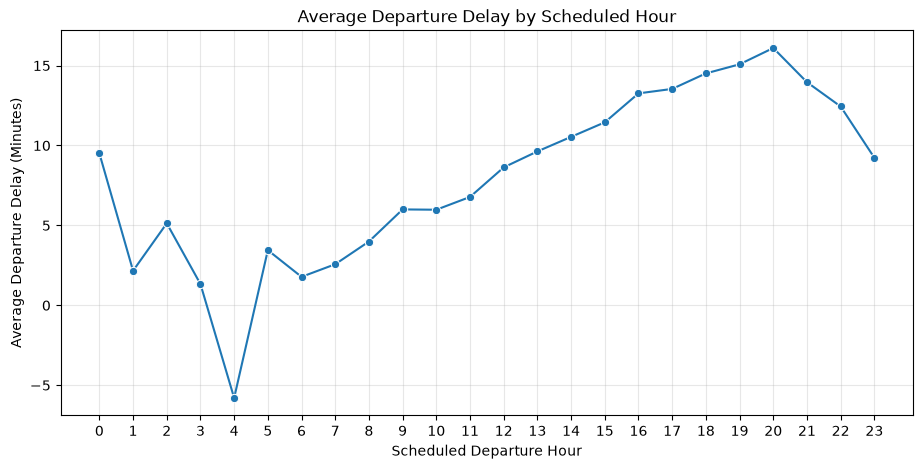

In [94]:

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=hourly_analysis,
    x=hourly_analysis.index,
    y='avg_departure_delay',
    marker='o'
)

plt.title('Average Departure Delay by Scheduled Hour')
plt.xlabel('Scheduled Departure Hour')
plt.ylabel('Average Departure Delay (Minutes)')
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()


- 8 PM (20:00): Highest average departure delay, approximately 16 minutes.



- 4 AM (04:00): Lowest average departure delay, approximately 6 minutes early.



- 12 PM–8 PM: Departure delays generally increase throughout the afternoon and evening.



- After 8 PM: Average delays begin to decrease.

In [95]:

print("Highest delay hour:")
print(hourly_analysis['avg_departure_delay'].idxmax())

print("\nLowest delay hour:")
print(hourly_analysis['avg_departure_delay'].idxmin())


Highest delay hour:
20

Lowest delay hour:
4


Perfect! Your results confirm:
- Highest average departure delay: 8 PM (20:00).
- Lowest average departure delay: 4 AM (04:00).

### Sprint 3

Hypothesis Testing.

Do flights operated by different airlines have significantly different average arrival delays?

Business question: Do different airlines have significantly different arrival-delay patterns?

Hypothesis testing helps us determine whether an observed difference in our dataset is statistically significant or could simply be due to random variation.

In [96]:

from scipy.stats import kruskal

airline_groups = [
    group['ARRIVAL_DELAY'].dropna().values
    for name, group in df.groupby('AIRLINE')
]

print("Number of airline groups:", len(airline_groups))


Number of airline groups: 14


In [97]:

statistic, p_value = kruskal(*airline_groups)

print("Kruskal-Wallis Statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject the Null Hypothesis (H0)")
    print("There is a statistically significant difference among airlines.")
else:
    print("Fail to Reject the Null Hypothesis (H0)")
    print("There is insufficient evidence of a significant difference.")


Kruskal-Wallis Statistic: 633.3974926411639
P-value: 5.772999045453124e-127
Reject the Null Hypothesis (H0)
There is a statistically significant difference among airlines.


p-value is much smaller than 0.05.

Therefore, we reject the null hypothesis.

Conclusion: There is a statistically significant difference in arrival-delay distributions among the 14 airlines.

In simple terms, the arrival-delay patterns are not the same across all airlines.

Important: This test tells us that at least one airline differs. It does not tell us exactly which airlines differ.

In [98]:

monthly_groups = [
    group['ARRIVAL_DELAY'].dropna().values
    for name, group in df.groupby('MONTH')
]

print("Number of monthly groups:", len(monthly_groups))


Number of monthly groups: 12


Hypotheses
- H₀ (Null): There is no statistically significant difference in arrival-delay distributions across the 12 months.
- H₁ (Alternative): At least one month has a significantly different arrival-delay distribution.

In [99]:
from scipy.stats import kruskal

statistic, p_value = kruskal(*monthly_groups)

print("Kruskal-Wallis Statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject the Null Hypothesis (H0)")
    print("There is a statistically significant difference across months.")
else:
    print("Fail to Reject the Null Hypothesis (H0)")
    print("There is insufficient evidence of a significant difference.")

Kruskal-Wallis Statistic: 508.2100354155759
P-value: 5.688851778204704e-102
Reject the Null Hypothesis (H0)
There is a statistically significant difference across months.


Since the p-value is much smaller than 0.05, we reject the null hypothesis.

Conclusion: There is a statistically significant difference in arrival-delay distributions across the 12 months.

This means at least one month's delay distribution differs from the others. It does not mean every month is significantly different.
- The Kruskal–Wallis H-test was performed to determine whether arrival-delay distributions varied significantly across the 12 months. The test produced an H-statistic of 508.21 and a p-value of 5.69 × 10⁻¹⁰². Since the p-value was below the 0.05 significance level, the null hypothesis was rejected. This indicates that arrival-delay distributions differ significantly across months.

In [100]:
weekday_groups = [
    group['ARRIVAL_DELAY'].dropna().values
    for name, group in df.groupby('DAY_OF_WEEK')
]

print("Number of weekday groups:", len(weekday_groups))

Number of weekday groups: 7


Hypotheses
- H₀: Arrival-delay distributions do not differ significantly across the seven days.
- H₁: At least one day has a significantly different arrival-delay distribution

In [101]:
from scipy.stats import kruskal

statistic, p_value = kruskal(*weekday_groups)

print("Kruskal-Wallis Statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject the Null Hypothesis (H0)")
    print("There is a statistically significant difference across weekdays.")
else:
    print("Fail to Reject the Null Hypothesis (H0)")
    print("There is insufficient evidence of a significant difference.")


Kruskal-Wallis Statistic: 149.2041402117795
P-value: 1.1398454498696864e-29
Reject the Null Hypothesis (H0)
There is a statistically significant difference across weekdays.


Since the p-value is below 0.05, we reject the null hypothesis.

Conclusion: At least one weekday has a significantly different arrival-delay distribution compared with the others.

### Confidence Interval

In [102]:
from scipy import stats
import numpy as np

arrival_delays = df['ARRIVAL_DELAY'].dropna()

mean_delay = np.mean(arrival_delays)
std_error = stats.sem(arrival_delays)

ci = stats.t.interval(
    confidence=0.95,
    df=len(arrival_delays)-1,
    loc=mean_delay,
    scale=std_error
)

print("Mean Arrival Delay:", mean_delay)
print("95% Confidence Interval:", ci)

Mean Arrival Delay: 3.9994499337883265
95% Confidence Interval: (np.float64(3.6654405686436653), np.float64(4.333459298932987))


- Based on this sample, we estimate that the true population mean arrival delay lies between approximately 3.67 and 4.33 minutes with 95% confidence.

- A 95% confidence interval was calculated to estimate the population mean arrival delay. The sample mean was 4.00 minutes, with a lower confidence limit of 3.67 minutes and an upper confidence limit of 4.33 minutes. This suggests that the population mean arrival delay is estimated to lie within this interval with 95% confidence.

In [104]:

import numpy as np
from scipy import stats

# 1. Airline-wise hypothesis test
airline_groups = [
    g['ARRIVAL_DELAY'].dropna().values
    for _, g in df.groupby('AIRLINE')
]

# 2. Month-wise hypothesis test
monthly_groups = [
    g['ARRIVAL_DELAY'].dropna().values
    for _, g in df.groupby('MONTH')
]

# 3. Weekday-wise hypothesis test
weekday_groups = [
    g['ARRIVAL_DELAY'].dropna().values
    for _, g in df.groupby('DAY_OF_WEEK')
]

# Perform Kruskal-Wallis tests
tests = {
    "Airline": stats.kruskal(*airline_groups),
    "Month": stats.kruskal(*monthly_groups),
    "Weekday": stats.kruskal(*weekday_groups)
}

print("HYPOTHESIS TEST RESULTS")
print("-" * 45)

for name, (statistic, p_value) in tests.items():
    print(f"\n{name}-wise comparison")
    print(f"Statistic: {statistic:.4f}")
    print(f"P-value: {p_value:.6e}")
    print("Decision:", "Reject H0" if p_value < 0.05
          else "Fail to Reject H0")

# 4. 95% Confidence Interval
arrival_delays = df['ARRIVAL_DELAY'].dropna()

mean_delay = arrival_delays.mean()
standard_error = stats.sem(arrival_delays)

ci = stats.t.interval(
    confidence=0.95,
    df=len(arrival_delays) - 1,
    loc=mean_delay,
    scale=standard_error
)

print("\n95% CONFIDENCE INTERVAL")
print("-" * 45)
print(f"Mean Arrival Delay: {mean_delay:.2f} minutes")
print(f"Lower Limit: {ci[0]:.2f} minutes")
print(f"Upper Limit: {ci[1]:.2f} minutes")


HYPOTHESIS TEST RESULTS
---------------------------------------------

Airline-wise comparison
Statistic: 633.3975
P-value: 5.772999e-127
Decision: Reject H0

Month-wise comparison
Statistic: 508.2100
P-value: 5.688852e-102
Decision: Reject H0

Weekday-wise comparison
Statistic: 149.2041
P-value: 1.139845e-29
Decision: Reject H0

95% CONFIDENCE INTERVAL
---------------------------------------------
Mean Arrival Delay: 4.00 minutes
Lower Limit: 3.67 minutes
Upper Limit: 4.33 minutes


Fearture engnering

In [105]:

import numpy as np

# 1. Departure time category
hour = df['SCHEDULED_DEPARTURE'] // 100

df['DEPARTURE_PERIOD'] = np.select(
    [
        (hour >= 5) & (hour < 12),
        (hour >= 12) & (hour < 17),
        (hour >= 17) & (hour < 21)
    ],
    ['Morning', 'Afternoon', 'Evening'],
    default='Night'
)

# 2. Flight duration category (SCHEDULED_TIME is in minutes)
df['FLIGHT_DURATION_CATEGORY'] = np.select(
    [
        df['SCHEDULED_TIME'] < 180,
        (df['SCHEDULED_TIME'] >= 180) &
        (df['SCHEDULED_TIME'] <= 360)
    ],
    ['Short', 'Medium'],
    default='Long'
)

# 3. Departure delay category
df['DEPARTURE_DELAY_STATUS'] = np.select(
    [
        df['DEPARTURE_DELAY'] < 0,
        df['DEPARTURE_DELAY'] == 0
    ],
    ['Early', 'On Time'],
    default='Delayed'
)

print("Feature engineering completed!")
print(df[
    ['DEPARTURE_PERIOD',
     'FLIGHT_DURATION_CATEGORY',
     'DEPARTURE_DELAY_STATUS']
].head())


Feature engineering completed!
  DEPARTURE_PERIOD FLIGHT_DURATION_CATEGORY DEPARTURE_DELAY_STATUS
0          Evening                   Medium                Delayed
1          Evening                    Short                Delayed
2          Morning                    Short                  Early
3          Morning                   Medium                Delayed
4          Morning                    Short                Delayed


In [106]:

# Distribution of engineered features

features = [
    'DEPARTURE_PERIOD',
    'FLIGHT_DURATION_CATEGORY',
    'DEPARTURE_DELAY_STATUS'
]

for col in features:
    print(f"\n{col.replace('_', ' ')}")
    print(df[col].value_counts())
    print("-" * 35)



DEPARTURE PERIOD
DEPARTURE_PERIOD
Morning      20568
Afternoon    15089
Evening      11185
Night         3158
Name: count, dtype: int64
-----------------------------------

FLIGHT DURATION CATEGORY
FLIGHT_DURATION_CATEGORY
Short     38524
Medium    10711
Long        765
Name: count, dtype: int64
-----------------------------------

DEPARTURE DELAY STATUS
DEPARTURE_DELAY_STATUS
Early      28058
Delayed    19060
On Time     2882
Name: count, dtype: int64
-----------------------------------


## Model evaluation

In [107]:

# FINAL BUSINESS FINDINGS

print("FLIGHT DELAY ANALYTICS - BUSINESS SUMMARY")
print("=" * 50)

# Overall delay
print("\n1. OVERALL ARRIVAL PERFORMANCE")
print("Average Arrival Delay:",
      round(df['ARRIVAL_DELAY'].mean(), 2), "minutes")

print("Percentage of Delayed Flights:",
      round((df['ARRIVAL_DELAY'] > 0).mean() * 100, 2), "%")

# Airline with highest average arrival delay
airline_delay = df.groupby('AIRLINE')['ARRIVAL_DELAY'].mean()
print("\n2. AIRLINE PERFORMANCE")
print("Highest Average Arrival Delay:",
      airline_delay.idxmax(),
      round(airline_delay.max(), 2), "minutes")

# Month with highest average delay
monthly_delay = df.groupby('MONTH')['ARRIVAL_DELAY'].mean()
print("\n3. MONTHLY PERFORMANCE")
print("Highest Average Arrival Delay Month:",
      monthly_delay.idxmax(),
      round(monthly_delay.max(), 2), "minutes")

# Weekday with highest average delay
weekday_delay = df.groupby('DAY_OF_WEEK')['ARRIVAL_DELAY'].mean()
print("\n4. WEEKDAY PERFORMANCE")
print("Highest Average Arrival Delay Day:",
      weekday_delay.idxmax(),
      round(weekday_delay.max(), 2), "minutes")

# Cancellation and diversion rates
print("\n5. OPERATIONAL DISRUPTIONS")
print("Cancellation Rate:",
      round(df['CANCELLED'].mean() * 100, 2), "%")

print("Diversion Rate:",
      round(df['DIVERTED'].mean() * 100, 2), "%")

# Main delay cause
delay_columns = [
    'AIR_SYSTEM_DELAY',
    'SECURITY_DELAY',
    'AIRLINE_DELAY',
    'LATE_AIRCRAFT_DELAY',
    'WEATHER_DELAY'
]

delay_totals = df[delay_columns].sum()
print("\n6. MAJOR DELAY CONTRIBUTOR")
print("Largest Delay Contributor:",
      delay_totals.idxmax(),
      round(delay_totals.max(), 0), "minutes")


FLIGHT DELAY ANALYTICS - BUSINESS SUMMARY

1. OVERALL ARRIVAL PERFORMANCE
Average Arrival Delay: 4.0 minutes
Percentage of Delayed Flights: 35.72 %

2. AIRLINE PERFORMANCE
Highest Average Arrival Delay: NK 14.51 minutes

3. MONTHLY PERFORMANCE
Highest Average Arrival Delay Month: 2 9.77 minutes

4. WEEKDAY PERFORMANCE
Highest Average Arrival Delay Day: 4 5.44 minutes

5. OPERATIONAL DISRUPTIONS
Cancellation Rate: 1.59 %
Diversion Rate: 0.24 %

6. MAJOR DELAY CONTRIBUTOR
Largest Delay Contributor: LATE_AIRCRAFT_DELAY 205967.0 minutes


Business insights and recommendations
Business insight	Recommendation
- NK has the highest average arrival delay.	->Review airline-specific operational and scheduling performance.
- February has the highest average monthly delay.	->Plan additional operational resources during this period.
- Thursday has the highest average weekday delay.	->Monitor Thursday schedules and turnaround operations.
- Late aircraft delay contributes the most delay minutes.	->Improve aircraft turnaround time and reduce delays carried over from previous flights.
- Air system delay is another major contributor.	->Improve coordination with airport and air traffic operations.
- 1.59% of flights were cancelled.	->Review cancellation reasons and strengthen disruption management.

# Flight Delay Analytics Using Python

## Project Conclusion

The Flight Delay Analytics project analyzed 50,000 flight records to identify patterns and major contributors to flight delays, cancellations, and operational disruptions.

Using Python, NumPy, Pandas, Matplotlib, Seaborn, and SciPy, the project involved data cleaning, preprocessing, exploratory data analysis, statistical testing, and feature engineering.

The analysis revealed an average arrival delay of approximately 4 minutes, with 35.72% of flights arriving late. Among the airlines analyzed, NK recorded the highest average arrival delay of 14.51 minutes. February and Thursday showed the highest average arrival delays among months and weekdays, respectively.

Late aircraft delays were identified as the largest contributor to total delay minutes, followed by airline delays and air system delays. The project also identified flight cancellations and diversions as additional operational challenges.

Statistical hypothesis testing confirmed significant differences in arrival-delay distributions across airlines, months, and weekdays. A 95% confidence interval estimated the population mean arrival delay to be between 3.67 and 4.33 minutes, subject to the sampling assumptions.

Feature engineering further enhanced the dataset by introducing departure-period, flight-duration, and departure-delay categories.

Overall, this project demonstrates how data analytics and statistical methods can help airlines understand operational inefficiencies, identify delay patterns, and make informed decisions to improve scheduling, reduce disruptions, and enhance passenger experience.